<a href="https://colab.research.google.com/github/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/analog_design_difficulty/analog_design_difficulty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Why Analog Design Remains Difficult Even When the Equations Are Known
### Coupled physics, provisional requirements, and engineering evidence, with a reproducible SKY130 sample-and-hold as the running example

| Team member | Affiliation | GitHub |
|---|---|---|
| Kazuki Fujita | Department of Electrical Engineering, Graduate School of Engineering, Tokyo University of Science | 771-8bit |

Licence: Apache-2.0 (`LICENSE`).

## 0. Beyond the Textbook Equations

Analog circuit theory is well developed. The MOS device equations, the small-signal model, and the canonical
structures — the differential pair, the current mirror, the cascode, the feedback amplifier, the switched-capacitor
circuit — are taught with expressions for their gain, bandwidth, noise, and error. A designer uses these results at
every step. They are where the design of a circuit starts, not where the engineering problem ends.

Each textbook result is derived with the rest of the circuit held fixed: a bias point, a load, a source impedance, a
small signal, a nominal process. In a real circuit those surroundings are other parts of the same circuit, and the
quantities interact physically. A stage's output impedance and the next stage's input capacitance form a pole
together; a switch releases its channel charge into the capacitor it was meant to connect; the bias point that sets
a transistor's transconductance moves with the signal, the supply, and the temperature; a capacitor that stores a
voltage carries the result of one operation into the next. Which of these interactions dominates an error changes
with operating point, signal level, stored state, timing, process, supply, and temperature (PVT), and with what the
layout adds. Analog design remains difficult when the equations are known because the quantities they describe are
coupled, and the strength of the coupling depends on the conditions of use.

Engineers do not solve such a coupled problem in one step. They write a provisional version of it: a parent
requirement taken from the system the block serves (here, the circuit that uses the output), and allocations that split it into pieces a person or a
test can check one at a time; models and testbenches that keep the effects relevant to one decision and leave
others out; block boundaries that decide what is designed together; circuit structures — feedback, buffering,
cascoding, differential signalling, switch and clock techniques — that weaken an inconvenient dependency; and a
verification plan that says what evidence is enough to freeze a result. Sensitivity analysis, parameter sweeps, and
numerical optimization search for good designs inside such a formulation. Choosing the formulation, and revising it
when evidence shows that one of its parts no longer supports the decision it was made for, is also design work.

These practices are established in analog and mixed-signal engineering and in systems engineering. This notebook
does not propose a new or universal analog-design methodology. It explains why the practices exist, which physical
difficulty each one addresses, and which assumption each one introduces. Two questions follow from that. AI systems
already take on parts of sizing, simulation, and layout, and may take on much more of the loop: does that change why
analog design is difficult, or how the difficulty is made tractable? And what does a junior analog designer need to
understand, beyond the circuit equations, to formulate, check, and revise this work — whether people or tools carry
it out?

To keep the argument concrete, the notebook uses one small circuit as a running example: a sample-and-hold front end
in the open SKY130 process, simulated with ngspice and reproducible from the saved results (Section 2). It serves as
a microscope for the issues above. It is not the subject of the notebook and not a sample-and-hold optimisation
tutorial, and one public circuit illustrates the argument without proving a general law of analog design.

In [1]:
# Setup, no output: locate the repository, load the saved closure result,
# define the figure helpers.
from pathlib import Path
import json
import os
import sys
from IPython.display import SVG, Image, Markdown, display

REPO = Path.cwd().resolve()
while not (REPO / "experiments" / "closure").is_dir() and REPO != REPO.parent:
    REPO = REPO.parent
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if not (REPO / "experiments" / "closure").is_dir() and IN_COLAB:
    # Opened alone in Colab: fetch only this project's folder from the
    # Code-a-Chip repository. The saved results need no ngspice or SKY130.
    import subprocess
    SRC = "https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io.git"
    SUB = "ISSCC27/submitted_notebooks/analog_design_difficulty"
    CLONE = Path("/content/sscs-ose-code-a-chip")
    if not (CLONE / SUB).is_dir():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                        "--sparse", SRC, str(CLONE)], check=True)
        subprocess.run(["git", "-C", str(CLONE), "sparse-checkout", "set",
                        SUB], check=True)
    REPO = CLONE / SUB
if not (REPO / "experiments" / "closure").is_dir():
    raise FileNotFoundError("project files not found: run this notebook "
                            "from its project folder")
if IN_COLAB:
    os.chdir(REPO)
FIG = REPO / "results" / "figures"
# explanatory drawings
# (scripts/draw_restart_diagrams.py, scripts/draw_diagrams.py)
DIAG = REPO / "assets" / "diagrams"
DATA = REPO / "results" / "data"      # first-cut evidence
# final verification of the selected design
CLOSURE = REPO / "results" / "closure" / "final" / "q1_nvt1"
final = json.loads((CLOSURE / "final_closure.json").read_text())

def show(name, width=900):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

def diagram(name):
    display(SVG(filename=str(DIAG / f"{name}.svg")))

## 1. Why analog design remains difficult

The established results of analog circuit theory — the MOS models in strong and weak inversion, small-signal gain
and output resistance, the poles of a loaded stage, feedback and stability, thermal and flicker noise, the charge a
MOS switch releases when it turns off (Razavi, 2017; Gray et al., 2009; Carusone et al., 2012) —
are needed for every design decision. Each describes one effect with the rest of the circuit fixed: the gain of a
stage at a given bias and into a given load, the settling of a loop that drives a given capacitance, the noise of a
resistor at a given temperature. A circuit has to meet its requirement when those fixed surroundings are the other
parts of the same circuit, and at every condition in which it will be used. Taken one at a time, the results do not
establish whether it does.

### Physical coupling

Analog quantities interact through a few recurring physical paths. Current flows through finite impedances: a stage
with finite output impedance changes its output voltage when the next stage draws current from it, and the next
stage's input capacitance sets a pole of the first. Charge moves through capacitances: a MOS switch releases its
channel charge into the nodes it connects, and gate-drain and gate-source capacitances couple a clock edge or a large
voltage swing into a node that should stay quiet. Circuits that share a supply line, a ground return, a bias line, or
the substrate interact through the impedance of the shared path, and bond wires and package traces add inductive
coupling. Each path connects quantities that a block diagram draws as separate.

Device limits decide how much these paths matter. A transistor has finite gain, a finite current with which to
charge a load, and finite voltage headroom before it leaves saturation; a stage that runs short of any of them stops
behaving as its small-signal model says. Every resistive element and every transistor channel adds noise, and a
bandwidth chosen for speed also decides how much of that noise reaches the output. Parasitic capacitances and
resistances add poles and paths that the schematic did not intend. Capacitors store charge, so the voltage a
capacitor holds at the end of one operation is the initial condition of the next, and the circuit's response depends
on its history.

Feedback belongs to a different category. It is a functional structure that engineers add on purpose, to make a
circuit less sensitive to finite gain, output impedance, and device variation, and it brings a coupling of its own:
whatever loads the loop changes its stability and its settling (Black, 1934; Razavi, 2017). Physical
interaction paths, device limits, stored state, and the structures added to control them are separate questions
about a circuit, not entries of one list.

### Nonlinearity and condition dependence

A MOSFET's drain current and the charge on its terminals are nonlinear functions of its terminal voltages. Its
transconductance `gm`, output conductance `gds`, incremental resistance, terminal capacitances, and channel charge
are therefore local, condition-dependent descriptions rather than fixed constants of the device; they, its threshold
and body effect, and even its region of operation change with the terminal voltages and with PVT
(Razavi, 2017; Gray et al., 2009). Small-signal quantities such as `gm` and `gds` are derivatives at one
operating point; one value does not describe the whole signal range. Even with unchanged
connectivity, the strength of each interaction above therefore changes with the operating point, the signal level,
the stored state, the timing of clocks and inputs, PVT, and the parasitics that implementation adds. An interaction
that is negligible at the nominal point can dominate at one end of the signal range or at a cold, low-supply corner,
and the mechanism that dominates the error can differ from one condition to the next. A design checked where one
mechanism is worst may fail where another one is.

### A requirement tree and a dependency network

A circuit is judged by a requirement at its boundary, set by the system it serves; in the running example, by what
the circuit that uses its output needs. To design
against it, engineers split the requirement into allocations that can be owned, measured, and checked one at a
time — so much error for settling, so much for offset, so much for noise. The result is a requirement hierarchy:
a block-level parent requirement captures what the enclosing system needs from the block and is decomposed into
allocations that can be owned, measured, and checked one at a time, following the structure systems-engineering
practice uses to manage requirements (NASA, 2016; Kundert et al., 2000).

The physical quantities that must satisfy those allocations do not form the same tree. One device size moves
several quantities at once: a wider transistor has lower resistance, more capacitance, and more channel charge. One
bias current sets gain, bandwidth, noise, headroom, and power together. The effects that separate allocations
address share these causes, trade against one another, and add, with signs, in the one quantity the parent
requirement constrains. Feedback and stored state close cycles: a load changes the loop that drives it, and the
error left by one operation becomes the starting point of the next. Design-structure analyses describe such
cyclically coupled parameters as groups that no sequential ordering resolves (Steward, 1981; Smith and Eppinger, 1997).

Figure 1 draws both structures for the small circuit used as the running example from Section 2 on: a driver that
charges a sampling capacitor through a switch, read later by a downstream circuit. Even this circuit has no
ordering in which each quantity can be fixed before the next.

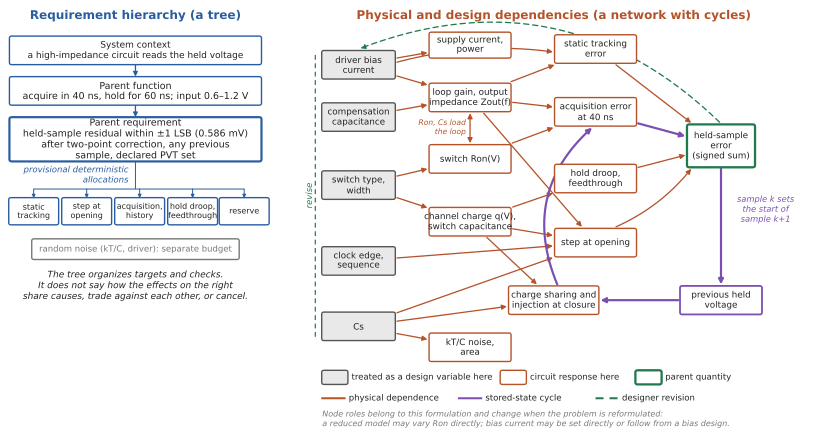

In [2]:
diagram("requirement_vs_network")

*Figure 1. Left: the requirement hierarchy of the running example, down to provisional working allocations and a
separate random-noise budget. Right: the physical and design dependencies that must satisfy it. Grey boxes are the
quantities this formulation treats as design variables, rust boxes the circuit responses that follow from them, and
the green box the parent quantity; purple arrows form the stored-state cycle from one sample to the next, and the
dashed path is a revision driven by evidence from the parent result. The roles are not properties of the quantities: a
reduced model may vary `Ron` directly, and a bias current may be set directly or follow from a bias circuit. A
simplified drawing of this circuit (Interpretation), not a complete model; the
same contrast arises in any block whose requirement is split into allocations.*

Hierarchy can coexist with coupling. Simon argues that many systems are *nearly* decomposable: interactions
within a subsystem are stronger than those between subsystems (Simon, 1962). Whether an interaction
is weak enough to ignore, however, depends on the required accuracy and the conditions, and at one part in a
thousand of a signal range many are not.

### Why this is not only an optimization problem

Engineers have established ways to move through a coupled design space. Sensitivity analysis shows which
parameters a performance responds to at a design point; structured parameter sweeps map a response over a few
variables; design centering places a design so that it keeps its specifications under process variation; numerical
and multi-objective optimization search many variables at once (Graeb, 2007; Mukherjee et al., 2000; Rutenbar et al., 2007). AI-based tools now do
parts of this search at a larger scale (Section 4). These methods make a coupled problem searchable, and a designer
who uses them well has a large advantage.

Each of them works inside a formulation that someone supplied: an objective and the metrics that stand for it, the
variables it may change, a circuit topology, a boundary that decides which blocks are designed together, a model or
testbench that evaluates each candidate, the operating conditions and verification set it is checked over, and a
rule for when the evidence is enough. A search returns a good answer to the problem it was given. It does not report
that its objective was a local allocation rather than the parent requirement, that its model leaves out the
interaction that will dominate in the connected circuit, that the worst condition lies outside its corner set, or
that a different circuit would remove the trade-off it is balancing. Changing the circuit so that a dependency
weakens — a cascode device that keeps the output swing off an input transistor's drain, feedback that divides an
output impedance, a differential pair that rejects a disturbance common to both inputs — changes the shape of the
trade-off instead of finding a better point on it. Much of analog design consists of choosing these parts of the
formulation and revising them when evidence shows that one of them no longer serves the parent requirement.
Section 3 takes them one at a time, and Section 4 asks what this means as more of the search is automated.

The fully coupled problem cannot be evaluated at full fidelity for every candidate either. Early in a design, the
circuit that would be simulated does not exist yet. Later, a credible verification of even a small block covers
many signal levels, input sequences, process corners, supplies, and temperatures (Section 3.5 counts them for the
running example), and a large table of passes and failures does not say which dependency to change. Engineers
therefore use deliberately incomplete representations: a requirement split into allocations, a model that keeps the
effects relevant to one decision, a testbench that excites one port, a boundary between blocks. These
representations make the coupled problem tractable. They are engineering choices, not the physics, and the designer
must recognize when one of them no longer supports the decision being made and revise it at the right level.

Section 2 introduces the small circuit that makes these ideas concrete. Section 3 then follows the established
practices one at a time, each from the difficulty it addresses to what the circuit showed.

## 2. The running example: a SKY130 sample-and-hold

This section introduces the small physical network used in the rest of the notebook to make Sections 1 and 3
concrete. A sample-and-hold suits this purpose because a few components already show the coupling of
Section 1: a feedback amplifier whose load changes when a switch closes, a switch whose resistance and channel charge
depend on the signal level, a capacitor that carries one sample's error into the next, and a requirement set by the
circuit that reads the held voltage.

The running example is a single-ended sample-and-hold front end on a 1.8 V supply in the open SKY130 process
(Figure 2). A closed-loop driver, an operational amplifier connected as a unity-gain follower, receives an input
voltage between 0.6 V and 1.2 V; a MOS sampling switch connects its output to a sampling capacitor `Cs` = 1 pF. The
downstream circuit that reads the held voltage is assumed to have a high input impedance and is not modelled.

A clock repeats every 100 ns. For the first 40 ns the switch is closed and the driver charges `Cs` toward the
input level (acquisition); for the remaining 60 ns `Cs` holds the sample while the downstream circuit reads it. The
input moves to the next level 1 ns after the switch opens, by up to the full range, and the next acquisition must
bring `Cs` from the previous held voltage to the new input level within 40 ns. This is the input timing the parent
requirement assumes, and the design is built and verified for it: the input changes during the hold, about 60 ns
before the switch closes again. A full-scale input step that coincides with switch closure, so that the driver must
follow the input and recharge `Cs` in the same 40 ns, is a separate diagnostic timing case, reported in Section 3.5
outside the pass/fail set.

When the switch closes, the driver sees the difference between the new target and the previous held voltage on
`Cs` as a sudden charge demand on its output, so the circuit has memory from one period to the next even though
each sample is meant to be independent.

**The requirement applies after a two-point correction.** The input span is 0.6 V, so a 10-bit-equivalent step is
`VLSB` = 0.6 V / 1024 ≈ 0.586 mV. At each verification condition, the offset and linear gain error of the held
voltage are estimated from repeated samples at 0.6 V and 1.2 V and removed by the straight line through those two
points; the parent requirement applies to what remains, which must stay within ±1 `VLSB` of the input. This is not
an absolute-accuracy requirement. Offset and gain, which drift with process, supply, and temperature, are excluded
from the metric on purpose; the residual keeps every error a straight line cannot remove — the parts that depend on
input level, on the previous sample, on timing, and on other non-affine effects. The correction (called calibration
in later sections) is part of how the metric is defined and verified; the notebook does not design a calibration
circuit or claim a particular product calibration scheme.

**What the brief freezes and what it treats as cost.** The brief freezes what the argument needs: the input
range, the 40 ns acquisition, the deterministic held-sample accuracy after the correction, a separate random-noise
budget (Section 3.1), behaviour over sequences of samples, and the declared PVT and verification domain with its
stability and model-validity checks. Supply current, device width, added capacitance, and circuit complexity have no
hard limits but are not free: each design response is judged by them and traded against them. A product would add
explicit power, area, interface, reliability, and system requirements; leaving them soft here isolates the
notebook's question — how coupled analog errors are formulated, diagnosed, revised, and closed.

Each counted sample is read in two windows (Figure 2, bottom layer), and both must pass. The early window E, 10–20 ns after the
switch opens, reads the held value after the opening transient: it contains the step the switch leaves when it
opens and, because the input moves to the next level 1 ns after opening, the first coupling of that change through the
open switch's capacitance. The late window L, from 6 ns to 1 ns before the next acquisition, is the latest moment a
downstream circuit could use the sample; it adds the droop and feedthrough that accumulate over the hold. Section 3.5 gives the exact measurement, including
how the first cycle after start-up is treated.

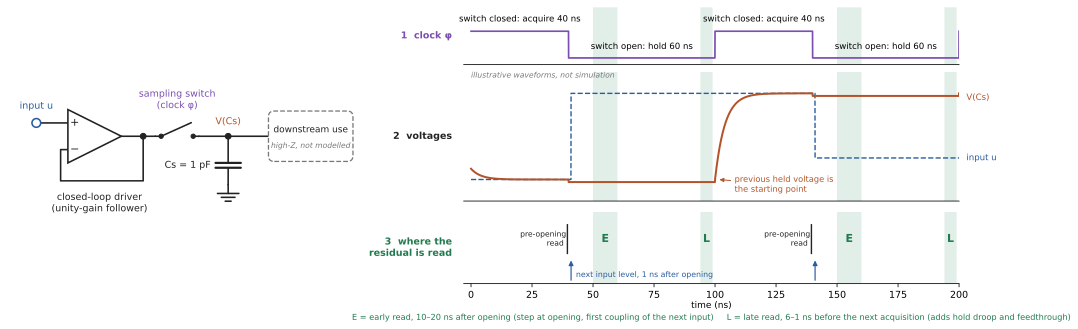

In [3]:
diagram("sampling_cycle")

*Figure 2. The running example. Left: driver (unity-gain follower), sampling switch, `Cs`, and the high-impedance
downstream use. Right, on one time axis: the clock (1); the input and the voltage on `Cs` over two 100 ns periods
(2, illustrative waveforms); and where the residual is read (3) — just before opening, in the early window E, and in
the late window L — with the next input level applied 1 ns after opening.*


The numbers in the rest of the notebook come from committed SKY130/ngspice results, which the notebook reads; two
cells in Section 3 can optionally rerun their bounded first-cut benches. The cell below reports the tools and PDK
that produced the saved results. Appendix A gives the commands that regenerate every result.

In [4]:
# The SKY130/ngspice simulations are long (first-cut evidence about 12
# minutes; final closure verification of the selected design several hours
# on 12 cores). This notebook reads their committed results;
# scripts/reproduce.py regenerates them (Appendix A).
import platform
import shutil
env = final["environment"]
print("selected design:           ", final["design"])
print("simulator (saved results): ", env["ngspice"])
print("SKY130 PDK (saved results):", env["sky130_sources"], "|",
      env["sky130_library"])
print("Python (saved results):    ", env["python"], "| numpy", env["numpy"],
      "| matplotlib", env["matplotlib"])
print("Python (this kernel):      ", platform.python_version())
print("ngspice on this machine:   ",
      "found" if shutil.which("ngspice")
      else "not found (not needed to read the saved results)")

selected design:            q1_nvt1
simulator (saved results):  ngspice-42
SKY130 PDK (saved results): open_pdks c6d73a35f524070e85faff4a6a9eef49553ebc2b | sky130A/libs.tech/ngspice/sky130.lib.spice
Python (saved results):     3.14.6 | numpy 2.5.4 | matplotlib 3.11.2
Python (this kernel):       3.14.6
ngspice on this machine:    found


## 3. Making a coupled analog design tractable

Section 1 described a coupled physical problem and the established practices engineers use to make it tractable.
This section takes those practices one at a time. Each subsection starts from the difficulty a practice addresses
and the engineering response, then shows what the running example revealed, and ends with what carries over to
other analog designs. The practices are not a fixed sequence that every project follows in this order. The example
passes through them on its way from a first formulation to a selected design, and in it several ran at the same
time.

### 3.1 Start with a provisional problem

Analog design has to start before the quantities it depends on exist. An amplifier's bandwidth target depends on
the load it will drive; the load depends on blocks that have not been designed; the error each block may contribute
depends on how the others turn out and on what the system calibrates away. An engineer who waits for a complete
problem never starts, and one who treats the first numbers as final has nothing to revise when they turn out wrong.
The established response is to write down a problem that is known to be incomplete, and to be explicit about which
of its statements are fixed and which are working guesses.

Each quantity in such a problem plays a role. A **parent requirement** is the higher-level requirement that the local allocations
below it are meant to support; the word names its place in the requirement decomposition, not a direction of
signal flow. It is fixed for the current design problem and changes only through an explicit requirement decision. A **provisional allocation** (a working target) splits the parent requirement into pieces that can be
designed and checked one at a time. A **design variable** is what the engineer chooses — a topology, a size, a bias
current. A **derived response** follows from the others and must be recomputed when they change. Treating these as
the same makes redesign arbitrary: an allocation treated as a requirement rejects designs that meet the parent
requirement, and a requirement treated as a working number can be relaxed whenever a design misses it.

These are roles in the current formulation, not properties of the quantities. In the running example, a switch
cannot be sized without a number for its on-resistance, which depends on how fast the driver will be, which depends
on the load the switch presents. In the first cut, `Ron` ≲ 1 kΩ was a working target, the gate width was the design
variable chosen to meet it, and the achieved on-resistance was a derived response; in a reduced model that sweeps
`Ron` directly, `Ron` is the design variable. Making the roles explicit tells the engineer what new evidence is
allowed to revise: a missed allocation can be re-split, while the parent requirement changes only by an
explicit requirement decision. Reformulating the
problem can change the roles, as the redesign below does.

The first cut split the parent requirement into an acquisition-settling allocation ε = 0.29 mV, about half of `VLSB`, and a
level-dependent remainder of ½ `VLSB`, shared equally between the switch's step at opening and driver static
tracking.
Settling 0.6 V to ε takes ln(0.6 V/ε) ≈ 7.6 time constants, so 40 ns allows about 5.3 ns in total; about one
fifth went to the switch, so `Ron` ≲ 1 kΩ at 1 pF. The switch was the smallest CMOS transmission gate, in 5 µm
steps, that met 1 kΩ over the range; the driver an existing two-stage Miller amplifier at 130 µA. For random sampled noise, the first-cut estimate
included only the ideal `kT/C` term of the sampling switch and `Cs`; driver transistor noise was not yet included and
is added in Section 3.3. This did not leave switching errors out: the level-dependent step at opening, which in the
transistor-level switch contains its channel-charge injection and clock feedthrough, is a deterministic error with
its own allocation above, and it was simulated separately from the random-noise estimate. 

A hand estimate flagged the switch: the 15 µm NMOS device holds roughly `W·L·Cox·(VDD − V − Vt)` ≈ 2.25 µm² × 8
fF/µm² × 0.7 V ≈ 13 fC near 0.6 V, and if about half reaches 1 pF the held voltage moves by several millivolts, an order of magnitude above `VLSB`
(Wegmann et al., 1987), with the PMOS charge of opposite sign making the step level-dependent.
Most of that step is offset and gain, which the correction removes, so whether the residual exceeds `VLSB` was a
question for simulation. *(Derived.)*

| Statement | First cut | Redesign |
|---|---|---|
| Downstream use | a high-impedance circuit reads the held voltage once per 100 ns period | same |
| Parent function | hold the input voltage (0.6–1.2 V) on `Cs`, non-inverting | same |
| Parent requirement (fixed) | ±1 `VLSB` after two-point correction | same |
| Verification of the parent requirement | nominal, `Cs` precharged to the target | repeated samples and sequences, 45 PVT conditions, two read windows |
| Provisional allocations | acquisition ε = 0.29 mV; step at opening 0.15 mV; static tracking 0.15 mV; switch `Ron` ≲ 1 kΩ; random: ideal `kT/C` of switch and `Cs` only (driver noise not yet included) | deterministic working allocations of Table 2, summing to 0.586 mV; random ≤ 0.25 `VLSB` rms, separate |
| Design variables | two-stage Miller driver, 130 µA; CMOS transmission gate 15/30 µm; `Cs` = 1 pF; 0.2 ns edges | Section 3.4 |
| Derived responses | `VLSB` = 0.586 mV; 7.6 time constants to settle 0.6 V to ε, 5.3 ns total in 40 ns; `kT/C` = 64 µV rms | same `VLSB`; `kT/C` 57–74 µV over −40 to 125 °C |

*Table 1. The provisional problem of the first cut and of the redesign, by the role of each statement.*


The redesign kept the parent requirement but changed how it was checked — real repeated samples and sequences instead of a
capacitor precharged to the target, 45 PVT conditions instead of nominal and two corners, a late read window — and
moved acquisition error from a separate allocation into the held-sample metric. Its working allocations (Table 2)
are named after the mechanism each one is meant to bound and the part of the cycle in which it acts. They are design
checks, not a decomposition of the held-sample error into independent physical sources: the mechanisms share causes
— switch width sets both the step at opening and the hold feedthrough — and the final measurement does not separate
them the same way. A reserve covers PVT spread and model and numerical uncertainty. Random noise has its own budget,
0.25 `VLSB` rms (146 µV); independent noise sources combine in variance, not linearly, and the noise budget is never
added into the deterministic residual. 

| Working check (deterministic) | Where it acts | Allocation | Where the final measurement contains it (Section 3.5) |
|---|---|---:|---|
| driver static tracking | end of acquisition, before opening | 0.15 mV | the residual read just before opening |
| level-dependent step at opening | switch opening | 0.15 mV | the change from just before opening to the early window E, together with the first coupling of the next input level |
| acquisition left over, previous-sample history | from closing through acquisition | 0.10 mV | not measured separately: whatever remains at opening is part of the residual read just before opening |
| hold droop, feedthrough of the next input | hold | 0.10 mV | the change from the early to the late window |
| reserve | — | 0.086 mV | PVT spread, model and numerical uncertainty |
| **sum** | | **0.586 mV = 1 `VLSB`** | conservative by construction: magnitudes add, while the physical effects can share causes or cancel |

*Table 2. Provisional deterministic working allocations (design checks) of the redesign. Read times are those of
Figure 2; Figure 3 places each check in the sampling cycle. Only the parent residual is pass/fail.*

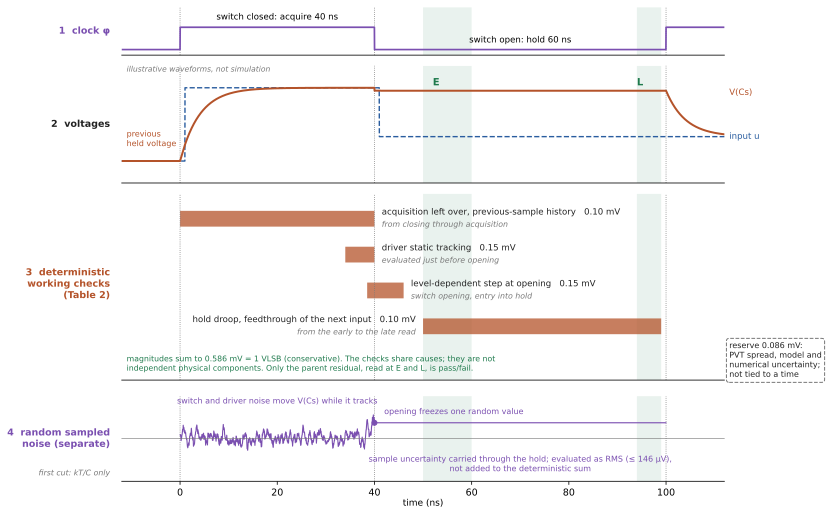

In [5]:
diagram("working_checks_cycle")

*Figure 3. Where the working checks of Table 2 act in one sampling cycle, on the time axis of Figure 2. Bars mark the
part of the cycle in which each deterministic check bounds a mechanism; the reserve is not tied to any instant. The
checks share causes and are not independent physical components. Random sampled noise is a separate lane: switch and
driver noise move `V(Cs)` while the switch is closed, the switch opening freezes one random value, and that sample
uncertainty is carried through the hold and evaluated as RMS noise, never added to the deterministic residual. In the
first cut this lane was estimated with `kT/C` alone. Illustrative, not simulation.*

A provisional allocation is a working hypothesis about how to make the parent requirement tractable, not a proven
complete decomposition of the physics. If a genuinely complete and sufficient set of lower-level requirements all
passed over the same conditions, the parent requirement would pass too; a failed parent requirement in that situation would mean
the decomposition itself was inadequate. Parent-level verification is what tests whether the provisional
decomposition was adequate. The allocations tell the designer where to look; they do not decide whether the design
passes, and specifications
passed down a hierarchy have to be informed by what the lower levels can achieve
(Rutenbar et al., 2007). The budget adds magnitudes, while the physical effects can partly
cancel in the held voltage. And margin consumes resources: because current, width, and capacitance are costs rather
than limits here (Section 2), tightening a local entry is never free — more loop gain costs current, headroom, or
compensation capacitance, and a smaller switch step costs conduction — and minimizing every local entry can spend
resources the parent result does not need. Section 3.4 shows both effects on a design decision.

The provisional problem is a working instrument, not a statement of the physics. Keeping the parent requirement,
the allocations, the design variables, and the derived responses apart is what later makes it possible to say which
statement new evidence contradicts, and therefore at which level the design may be revised.

### 3.2 Characterize where the first cut holds

A design result — a settling time, an offset, a phase margin, a held-sample error — is produced under stated
conditions: a bias point, a signal level, a previous state, a timing, a process corner, a supply, a temperature, a
model, and a testbench. Section 1 explained why each of these can change which physical effect matters. The
operating point sets each device's transconductance, output conductance, and saturation margin; the signal level
moves a switch's gate overdrive; the stored state sets how much charge must move at the next event; timing decides
whether one transient has finished when the next begins; PVT shifts thresholds, mobilities, and headroom; and
implementation adds parasitics. A single number therefore says how the circuit behaved at one point, not whether the
requirement holds where the circuit will be used.

The engineering response is to replace "what is the number?" by "over which conditions does this named
requirement hold?" A characterization states the requirement, the metric, and the grid of conditions on which it was
evaluated, and reads the result as a pass/fail or performance region on that grid. Designing for an operating range
and for process variation rather than for a nominal point is long-standing practice in analog design automation
(Mukherjee et al., 2000; Graeb, 2007). Choosing the grid is itself a design
decision: it has to contain the condition where each mechanism that matters is worst, and those conditions differ
from one mechanism to another. A grid of representative points is also not a continuous sweep, and the reading must
say so.

In the running example, the acquisition check of the first cut passed comfortably over the limited conditions
initially tested. At `tt`, 27 °C,
1.8 V it met the acquisition allocation at all nine combinations of target and previous voltage in
{0.6, 0.9, 1.2} V: worst error at 40 ns 0.011 mV against ε = 0.29 mV, last crossing of ε at 29.7 ns. The full-scale
transitions also passed at `ss` and `ff`, 27 °C. The held-sample working allocations did not close, and neither did
the parent requirement. At nominal, with `Cs` precharged to the target and seven held levels, the level-dependent
step at opening was 0.83 mV against its 0.15 mV allocation, driver static tracking about 0.33 mV against 0.15 mV, and
the held-sample residual after the two-point correction 0.64 mV, above `VLSB` (0.586 mV). The two components partly
cancel in the residual, which is why it is smaller than the step alone. *(Observed.)* 

The sequential bench of the final verification (Section 3.5), in which each held sample is the starting state of
the next, evaluated the first cut at seven screening conditions, a reduced set used to assess candidates before
final verification (Figure 4). At nominal it gives the same number from a different bench, 0.645 mV (1.10
`VLSB`); with the input changing during the hold, the previous sample changes the residual by only 0.014 mV.
Away from nominal, two different mechanisms fail at two different places. At −40 °C and the low supply, with `ss` and `sf` devices (`sf`: slow NMOS / fast PMOS; `fs`: fast NMOS / slow PMOS), the residual is 115 mV and 46 mV (196
and 78 `VLSB`). There the transmission gate stops conducting at mid-scale: with about 0.7–0.9 V of gate drive on
each device and body-raised thresholds of similar size, neither device is on, so the switch barely
conducts at mid-scale and acquisition does not finish. At the `fs` corner, at −40 °C and low supply
and at 125 °C and high supply, the residual is 1.14 and 2.04 `VLSB` with the switch conducting normally. There the
driver's static tracking error reaches about 1 mV: with a 0.6 V input, the tail transistor of the low-threshold
input pair is pushed into triode, so the tail current — and with it the amplifier's systematic offset — changes
with signal level, and the amplifier's modest DC open-loop gain (42–57 dB) does not suppress it. Two conditions
pass (`ff` and `sf` at 1.98 V, 125 °C, with 0.69 and 0.96 `VLSB`). *(Observed.)*

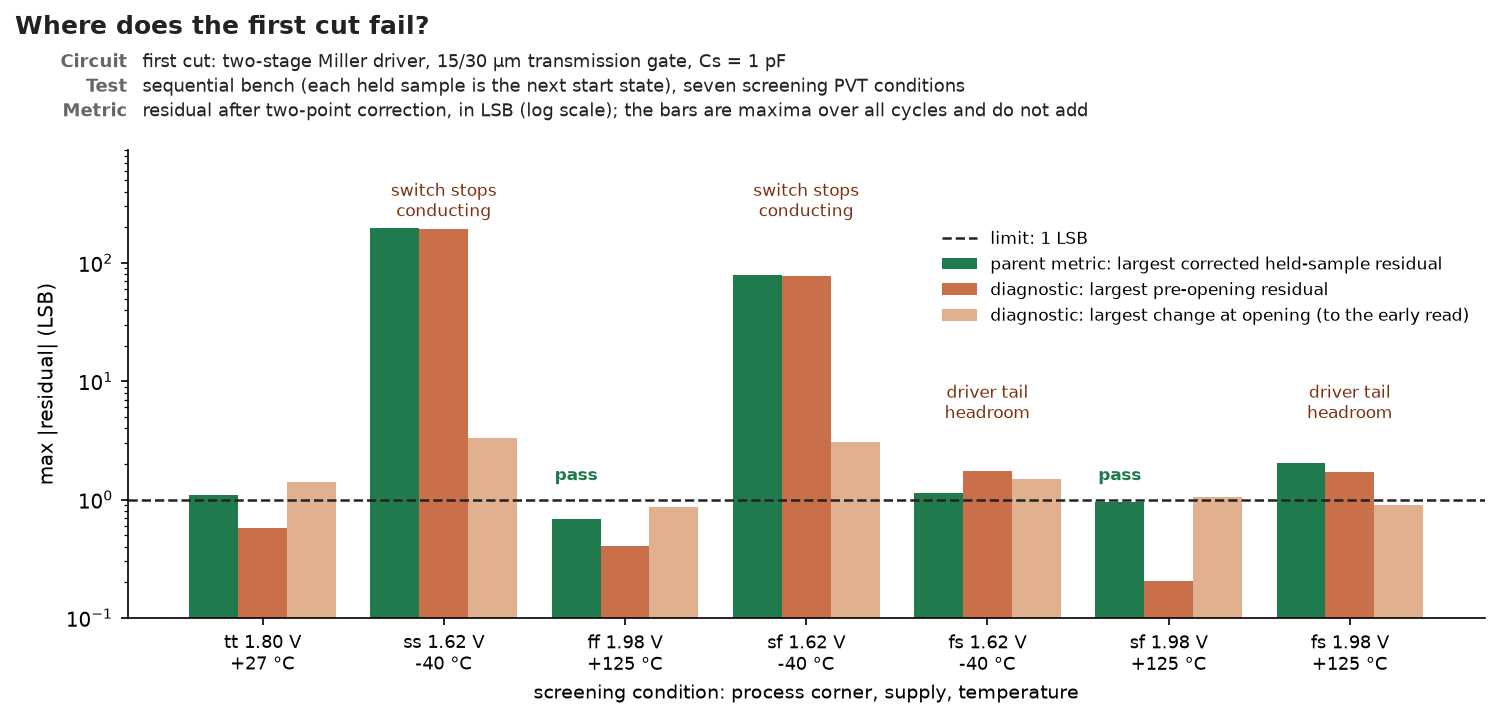

In [6]:
show("figure_f2_screening_map")

*Figure 4. Where the first cut fails on the sequential bench. Green: the parent metric; rust: the residual read just
before opening and the change at opening, as diagnostics (maxima over all cycles, so they do not add). The
transmission-gate conduction gap (`ss`/`sf`, −40 °C, 1.62 V) and the driver's tail headroom (`fs`) fail at different
corners, so no single corner characterizes the design. Screening supplies were 1.62 V and 1.98 V; the final set uses
1.60 V and 1.95 V.*

The failures sit in different places because each condition changes which physical effect matters. In this circuit
the signal level moves the switch's gate overdrive, and so its on-resistance and channel charge; in a follower it
also moves the amplifier's input common-mode voltage, which pushed the first cut's tail into triode. The previous
held voltage sets the charge the driver must supply when the switch closes; the switch and clock state decide whether
`Cs` loads the driver at all, the edge times how channel charge divides at opening, and the input timing whether
the driver is still settling when the switch closes. Process, supply, and temperature shift thresholds, mobilities,
and headroom, which closed the transmission gate's conduction window at cold, low supply. An interaction that was
negligible where the first cut was checked dominated elsewhere.

Three things follow. A working check that passes at every tested point — here acquisition — does not show that
the parent requirement is met; only the parent-level check decides that. The first cut had been checked at nominal for the held sample and at two room-temperature corners for
acquisition, a small part of the domain the requirement covers, and the worst cases lay outside it. And **no single
corner is worst for every mechanism compared here**: the switch fails at cold and low supply, the driver at the `fs`
corner, and later candidates showed settling problems at hot and low supply. A matrix pruned to the corner that is
worst for one mechanism would miss the others, which is why the final verification runs all 45 combinations of five
process corners, three supplies, and three temperatures. The grid between points matters too: the level-dependent
step at opening of the first-cut gate peaks near 1.0 V, between the 0.9 V and 1.2 V points of a three-level grid, which is why the
held-sample checks use seven or more levels. 

Characterization therefore reports a region on a stated grid against a named requirement, rather than one nominal
number or an implied guarantee between points that were never simulated. The region is also what directs the next
decision: it shows which mechanism fails where, and therefore which dependency a design change has to address.

### 3.3 Let implementation expose what the first cut missed

Every model, testbench, and block decomposition keeps some of the physical paths of Section 1 and leaves others out.
That is deliberate: a block cannot be designed against the whole circuit at once. A driver may be designed against a
resistor and a capacitor standing in for its load; an amplifier may be characterized with a step at its input; a
block may be simulated without the supply impedance, substrate, and package it will share with others. A
representation that omits a path is adequate for decisions in which that path does not matter, and only for those.
Whether an omission is acceptable is therefore a property of the decision, not of the model.

An omission is usually invisible within the representation itself. It becomes visible as more of the physical
circuit is included: connecting the actual neighbouring circuit instead of a model of it, exciting a block at the
port where the real disturbance enters, adding transistor detail, letting the stored state propagate from one
operation to the next, or adding layout parasitics. Mixed-signal practice runs connected and mixed-level tests
because an isolated testbench may not reproduce the loading and signal sequences of the connected system
(Kundert et al., 2000; Chang and Kundert, 2007). Read more broadly, the physical implementation and
the composition of blocks are themselves a source of design knowledge, not only a check of decisions already made
*(Interpretation)*. The running example produced four such exposures. Its benches use ideal supply and ground and no
substrate or package network, so the shared-impedance paths of a real layout are not exercised in this study.

The first concerns the representation of the switch given to the driver designer: `Cs`, the voltage range, 40 ns,
and one linear resistance `R_if` = 744 Ω, the transmission gate's largest DC on-resistance over the range. For
transitions it was adequate or conservative: the driver settled up to 2.3 ns later against `R_if` than against the
real gate, so for inputs that may start from any previous voltage no acquisition allocation passes the block test and
fails the connected circuit. In a fixture where `Cs` starts exactly at the target, the same representation was badly
misleading: it supports an acquisition of 0.8 ns where the connected circuit needs 10.3 ns (Figure 5). The
resistance omits the turn-on event: when the switch closes, its complementary gate edges couple charge into the
driver output (+26 mV at 0.6 V, +14 mV at 0.9 V, −30 mV at 1.2 V), a capacitive path the resistor does not contain.
With the same driver, switch, and simulator, the representation is adequate for one decision and inadequate for
another; what changes is the excitation (whether `Cs` starts at the target) and the allocation. *(Observed, first cut.)*

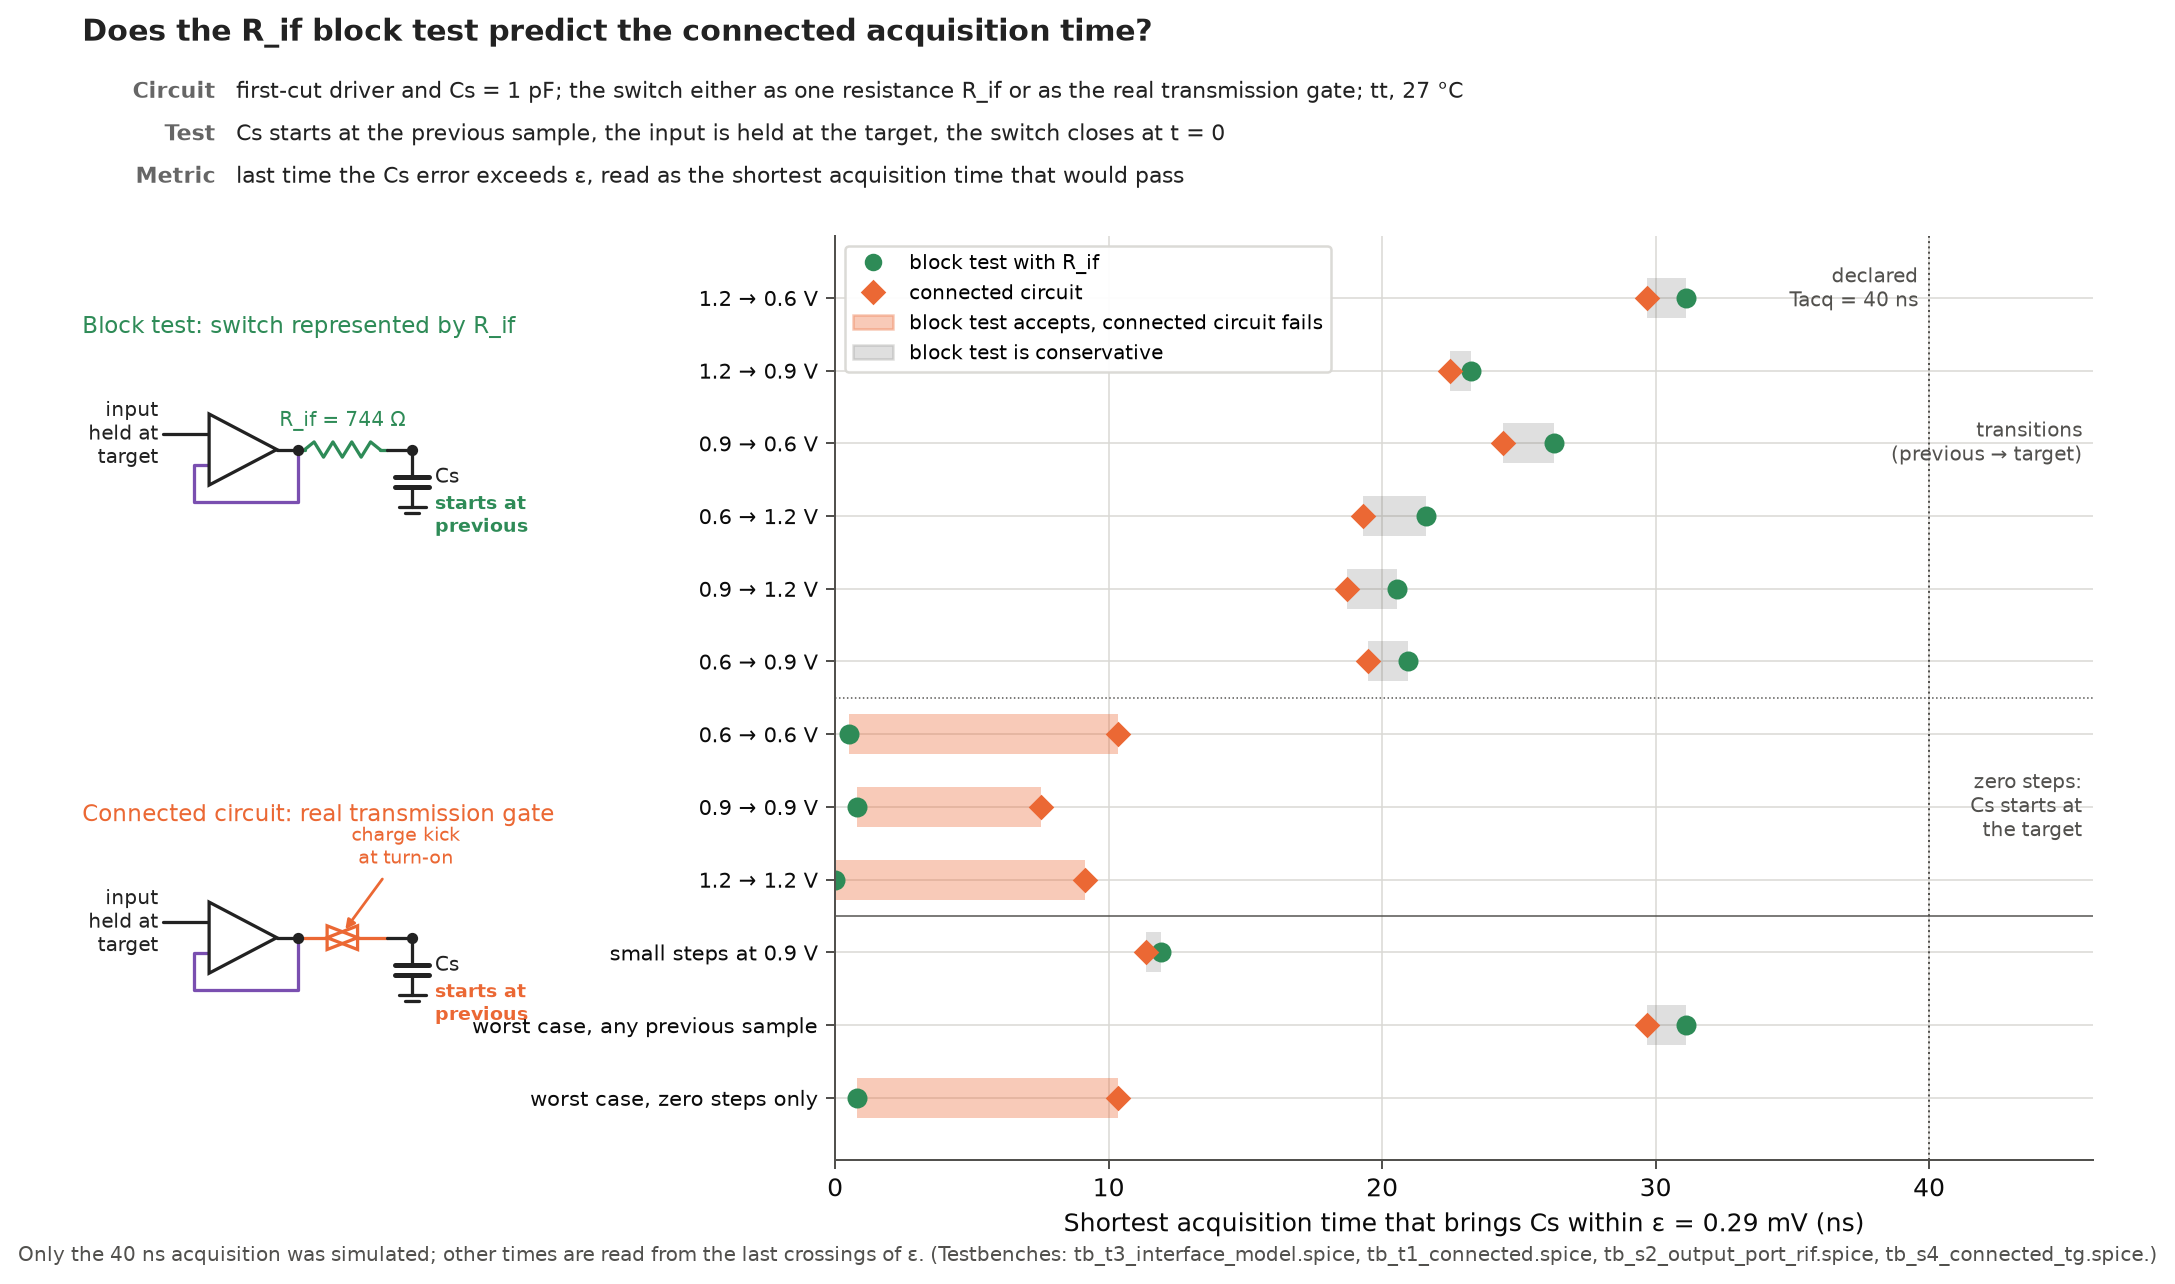

In [7]:
show("figure_sky130_acquisition_window")

*Figure 5. The same acquisition test with the switch represented by `R_if` (left, top) and with the real
transmission gate (left, bottom). Conservative for transitions; when `Cs` starts at the target, the block test
accepts acquisition times between 0.8 and 10.3 ns that the connected circuit rejects, because `R_if` has no turn-on
event. The same representation is adequate for one decision and not for another.*

**Try it.** The cell below compares, for one previous/target pair, the driver's block test with an input step, the
driver loaded by `R_if` and excited at its output port, and the connected circuit with the real gate, and prints
when each error last exceeds ε. Equal `PREVIOUS` and `TARGET` give the zero-step case of Figure 5; 0.6 and 1.2 give a
transition, where the input-step and output-port tests also differ (Section 3.5). `SOURCE = "spice"` reruns these
benches instead of reading the saved waveforms.

output port + R_if   last |error| ≥ ε at 0.45 ns
connected TG         last |error| ≥ ε at 10.30 ns


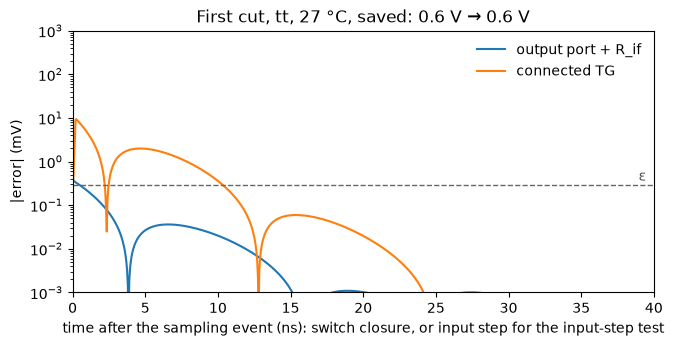

This cell shows 0.6 V → 0.6 V; Figure 5 reports the worst zero-step input level, so the times can differ.
(Separately, the saved traces read here are on a 50 ps grid.)


In [8]:
# Try it: one acquisition of the first cut (tt, 27 °C) from PREVIOUS to
# TARGET (each 0.6, 0.9 or 1.2 V) on up to three benches.
# SOURCE = "saved": the committed waveforms behind this notebook (default).
# SOURCE = "spice": rerun only these benches (needs ngspice and SKY130A;
# about a minute; output goes to a temporary folder, not to results/).
SOURCE = "saved"
PREVIOUS, TARGET = 0.6, 0.6
# any of: "input step", "output port + R_if", "connected TG"
BENCHES = ["output port + R_if", "connected TG"]

import csv
import numpy as np
import matplotlib.pyplot as plt
EPS = 0.6e3 / 1024 / 2   # acquisition allocation ε of the first cut, mV
traces = {}   # bench -> (time in ns, error in mV)
if SOURCE == "spice":
    sys.path.insert(0, str(REPO / "experiments" / "experiment_a" / "sky130"))
    import interactive
    traces = interactive.excitation(PREVIOUS, TARGET, BENCHES)
else:
    CODE = {"input step": ("a", "out"), "output port + R_if": ("b", "samp"),
            "connected TG": ("c", "samp")}
    with open(DATA / "sky130_waveforms_tt.csv") as fh:
        rows = list(csv.reader(fh))
    head, wav = rows[0], np.array(rows[1:], dtype=float)
    for bench in BENCHES:
        test, node = CODE[bench]
        col = f"{test}_{TARGET:.1f}_{PREVIOUS:.1f}_{node}_err_mV"
        if col in head:
            traces[bench] = (wav[:, 0], wav[:, head.index(col)])
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for bench in BENCHES:
    if bench not in traces:
        print(f"{bench:20s} not run for this pair "
              "(the input-step test needs a change of input level)")
        continue
    t, err = traces[bench][0], np.abs(traces[bench][1])
    keep = (t >= 0) & (t <= 40) & ~np.isnan(err)
    above = np.flatnonzero(keep & (err >= EPS))
    last = f"{t[above[-1]]:.2f} ns" if above.size else "never above ε"
    print(f"{bench:20s} last |error| ≥ ε at {last}")
    ax.semilogy(t[keep], np.maximum(err[keep], 1e-4), label=bench)
ax.axhline(EPS, color="0.4", ls="--", lw=1)
ax.text(39.5, EPS * 1.25, "ε", ha="right", color="0.3")
ax.set_xlabel("time after the sampling event (ns): switch closure, "
              "or input step for the input-step test")
ax.set_ylabel("|error| (mV)")
ax.set_title(f"First cut, tt, 27 °C, {SOURCE}: {PREVIOUS} V → {TARGET} V")
ax.set_xlim(0, 40)
ax.set_ylim(1e-3, 1e3)
ax.legend(frameon=False)
plt.show()
print(f"This cell shows {PREVIOUS} V → {TARGET} V; Figure 5 reports the "
      "worst zero-step input level, so the times can differ.")
if SOURCE != "spice":
    print("(Separately, the saved traces read here are on a 50 ps grid.)")

The second came from a bootstrapped switch tried during the redesign (Section 3.4; the selected design does not use
it). Its first variant charged the boost capacitor through a PMOS device. On the sequential bench, the same target held after a 0.6 V and after a 1.2 V sample differed
measurably. At turn-on the charging device was still conducting while the boost capacitor's bottom plate began to
follow the input node, which charge sharing with the previously held `Cs` had disturbed, so the boost charge, and with it the gate
drive, depended on the previous sample. Charging the capacitor through a clock-boosted NMOS that turns off first
removed most of the effect. A fixture that precharges `Cs` to the target cannot show this dependence by
construction, because previous and target voltage are equal there. *(Observed.)* 

The third was noise. The first cut counted sampled noise as `kT/C`, 64 µV rms at 1 pF, which is the noise of the
switch alone. With the driver included, the noise on `Cs` was about 263 µV rms (Table B.1), four times larger: the
driver's white noise extends over its closed-loop bandwidth of roughly 50–100 MHz, and `Cs` samples all of it. For
the later driver candidates this term, not `kT/C`, decided the noise budget. *(Observed.)* 

The fourth sat inside the driver. A redesigned driver settled a full-scale step to 0.05 mV only after about 100 ns,
and even a 10 mV step left a 0.2 % error at 40 ns. Bypassing nodes one at a time found the path: the output swing
coupled through the gate-drain capacitance of the large output sink transistor into the shared bias line (about 3
pF and 4 kΩ, τ ≈ 12–15 ns), which modulated the tail and sink currents. Biasing the
sink device from its own diode removed the path (settling of a full-scale input step to 0.05 mV in 46–61 ns,
with the input applied at the start of the hold). A bias line drawn as one node was a shared impedance between a
precision current source and a large output device. *(Observed.)* 

Each exposure revised something different: an interface representation and the excitation it may be used for, a
switch circuit, a budget's noise estimate, and a bias network. None could appear inside the representation that
omitted it. The general consequence is that a representation is adequate or inadequate for a decision, and that the
connected circuit, the real excitation port, and the propagated state are where its omissions show up. When one of
them reveals an omitted interaction, the designer must decide whether to change the circuit or the representation,
and which decisions made against the old representation have to be revisited.

### 3.4 Respond at the right level

A failed parent result rarely says what to change. Evidence can point to any of several levels of the design:

- the parent requirement or a provisional allocation — re-split a budget, or, by an explicit requirement decision,
  change the parent requirement;
- an operating condition — a bias current, a supply, a clock edge or a timing;
- transistor sizing within a fixed circuit;
- the circuit structure of one block — a different switch circuit, a cascoded or folded stage, a separate bias path;
- the functional structure — adding feedback, a buffer, a differential path, or a sampling function where there was
  none;
- the model or interface representation one block is designed against;
- the verification — which conditions, sequences, and read times count;
- the design scope — which blocks are designed and verified jointly (Section 3.6).

A change at the wrong level can improve a local number while the parent result stays put or gets worse, and the
easiest level to reach is usually sizing. The evidence may call for revising a requirement, an allocation, a size, a
circuit, a model, or a test; it may also point to a circuit change that weakens the troublesome dependency itself.
The running example exercised only some of these levels. Its parent requirement and its sample-and-hold function
stayed fixed throughout; what changed were sizes, the circuit of the switch and of the driver within the same
functional structure, the interface representation, the allocation, the verification domain, and finally the
switch's device choice. The response went through four stages.

#### A local improvement can worsen the parent residual

Here the *step at opening* (the hold step, or pedestal) is the uncorrected change of the held voltage across switch
opening on the zero-step hold bench, and its *level-dependent part* is what the two-point correction leaves of it;
the early-hold component `r_P` of Section 3.5 is broader. Half-size dummy switches, the textbook remedy for the step
at opening (Eichenberger and Guggenbühl, 1990), reduced the uncorrected step about fivefold but its level-dependent
part only 1.8-fold (0.83 → 0.46 mV), and the parent residual got worse (0.64 → 0.78 mV). The gate's negative
level-dependent step had been partly cancelling the driver's
positive static residual; the dummies changed its sign over 0.7–0.9 V, so the two added.

In a width ladder the level-dependent step scaled almost exactly with width (0.09, 0.20, 0.38, 0.83, 1.91 mV from one
eighth to double width), while the worst acquisition moved only from 29.7 to 32.2 ns: the 1 kΩ on-resistance
allocation had restricted the switch more than this driver needed. By the local allocation for the step at opening, the narrowest gate
was best; by the signed parent residual at nominal, half width (0.19 mV) ranked ahead of quarter (0.23 mV) and
eighth (0.27 mV) (Figure 6). The half-width pass rested on two physically unrelated errors — a driver headroom
effect and a switch threshold effect — having opposite signs at `tt`, 1.8 V, 27 °C; the narrower gates'
level-dependent steps were small enough not to need that cancellation. *(Observed, first cut.)*

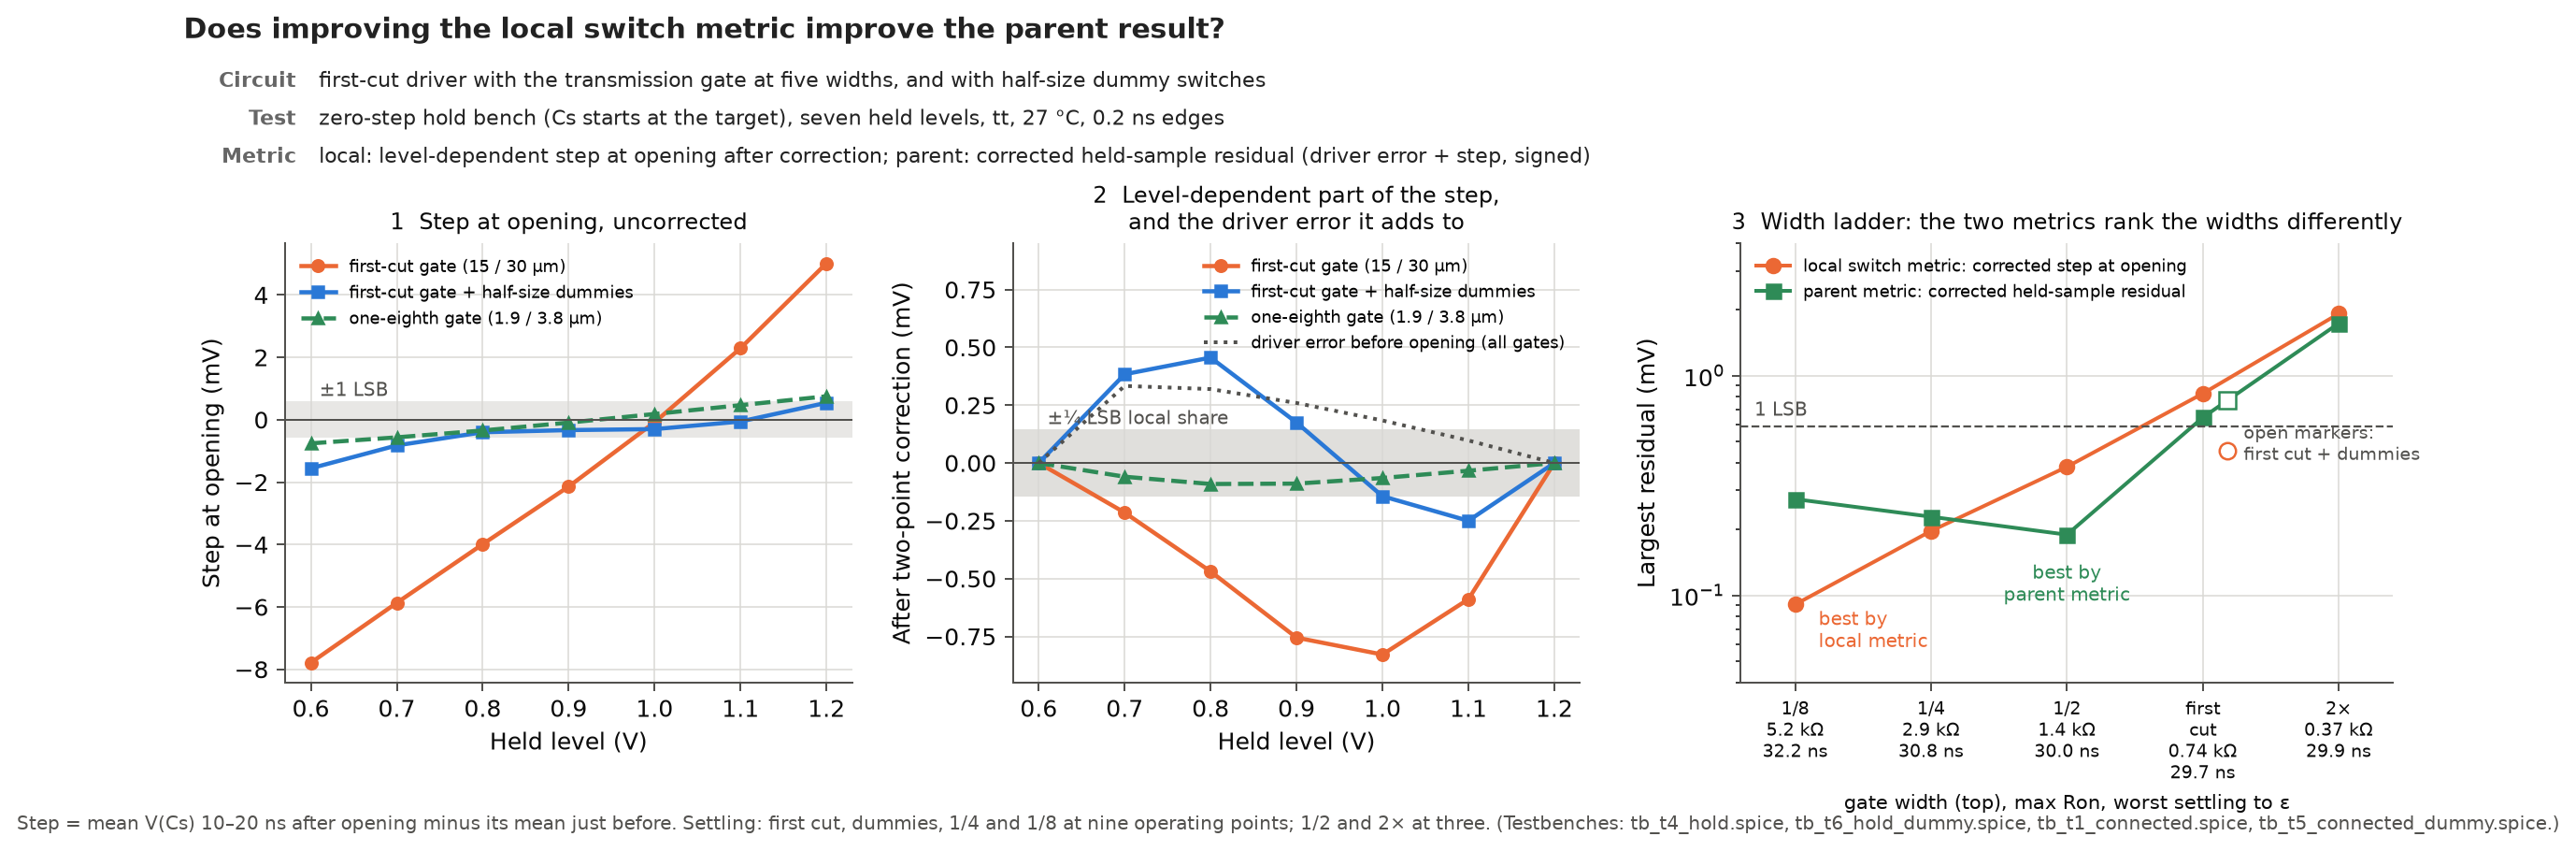

In [9]:
show("figure_sky130_held_sample")

*Figure 6. The step at opening of the first-cut gate, the gate with dummies, and the width ladder, on the zero-step
hold bench. Panel 3 ranks the widths by the local switch metric and by the corrected held-sample residual: the
narrowest gate is best by the first, half width by the second. The cell below reproduces the ranking.*

**Try it.** `METRIC = "local"` ranks the five widths and the dummy variant by the largest level-dependent step at
opening, which the switch's local allocation constrains; `METRIC = "parent"` ranks them by the largest held-sample residual after
correction, which the requirement constrains. `SOURCE = "spice"` reruns the hold bench for all six variants instead
of reading the saved results.

ranked by the local metric (best first); limits: local allocation 0.146 mV, parent requirement 0.586 mV
    variant                 local (mV)  parent residual (mV)
1   1/8 width                    0.091                 0.274
2   1/4 width                    0.196                 0.228
3   1/2 width                    0.384                 0.189
4   first cut + dummies          0.456                 0.776
5   first cut (15/30 µm)         0.828                 0.645
6   2× width                     1.913                 1.729


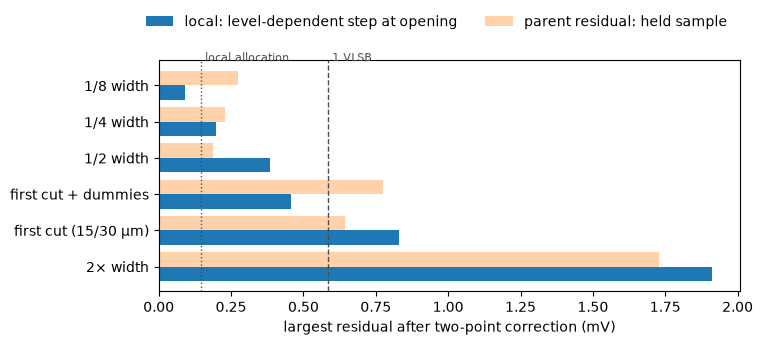

Nominal zero-step bench only. Over PVT the 1/2-width gate reaches 296 VLSB at ss, -40 °C, 1.62 V (text below).


In [10]:
# Try it: rank the first-cut gate variants (tt, 27 °C, zero-step bench)
# by a local or by the parent metric.
# "local": largest level-dependent step at opening (after correction)
# "parent": largest held-sample residual after correction
METRIC = "local"
# SOURCE = "saved": the committed width-ladder results (default).
# SOURCE = "spice": rerun the hold bench for all six variants (needs ngspice
# and SKY130A; a few minutes on several cores; temporary folder).
SOURCE = "saved"

import matplotlib.pyplot as plt
if SOURCE == "spice":
    sys.path.insert(0, str(REPO / "experiments" / "experiment_a" / "sky130"))
    import interactive
    hs = interactive.width_ladder()
else:
    summary = DATA / "sky130_followup_summary.json"
    hs = json.loads(summary.read_text())["held_sample"]
NAMES = {"eighth": "1/8 width", "quarter": "1/4 width", "half": "1/2 width",
         "chosen": "first cut (15/30 µm)", "double": "2× width",
         "dummy": "first cut + dummies"}
LOCAL, PARENT = "max_residual_hold_step_mV", "max_residual_held_error_mV"
key = {"local": LOCAL, "parent": PARENT}[METRIC]
order = sorted(NAMES, key=lambda n: hs["variants"][n][key])
print(f"ranked by the {METRIC} metric (best first); "
      f"limits: local allocation {hs['share_mV']:.3f} mV, "
      f"parent requirement {hs['VLSB_mV']:.3f} mV")
print(f"{'':4s}{'variant':22s}{'local (mV)':>12s}"
      f"{'parent residual (mV)':>22s}")
for i, n in enumerate(order, 1):
    v = hs["variants"][n]
    print(f"{i:<4d}{NAMES[n]:22s}{v[LOCAL]:12.3f}{v[PARENT]:22.3f}")
fig, ax = plt.subplots(figsize=(7.5, 3.0))
y = range(len(order))
ax.barh([i + 0.2 for i in y], [hs["variants"][n][LOCAL] for n in order],
        height=0.4, label="local: level-dependent step at opening",
        alpha=1.0 if METRIC == "local" else 0.35)
ax.barh([i - 0.2 for i in y], [hs["variants"][n][PARENT] for n in order],
        height=0.4, label="parent residual: held sample",
        alpha=1.0 if METRIC == "parent" else 0.35)
ax.axvline(hs["VLSB_mV"], color="0.3", ls="--", lw=1)
ax.text(hs["VLSB_mV"], -0.6, " 1 VLSB", color="0.3", va="bottom",
        fontsize=8)
ax.axvline(hs["share_mV"], color="0.3", ls=":", lw=1)
ax.text(hs["share_mV"], -0.6, " local allocation", color="0.3", va="bottom",
        fontsize=8)
ax.set_yticks(list(y))
ax.set_yticklabels([NAMES[n] for n in order])
ax.invert_yaxis()
ax.set_xlabel("largest residual after two-point correction (mV)")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.08),
          ncol=2)
plt.show()
print("Nominal zero-step bench only. Over PVT the 1/2-width gate reaches "
      "296 VLSB at ss, -40 °C, 1.62 V (text below).")

The cancellation did not survive the declared domain: at `ss`, −40 °C, 1.62 V the half-width gate's residual was
296 `VLSB`, because the conduction gap of Section 3.2 is worse for a narrower switch, and the narrowest gate cannot
conduct there either (Observed). The width ladder is a small, manual instance of the search methods of Section 1;
the objective it is ranked by matters independently of how the search is done. 

#### Change the dependency, not only the value

A characteristic analog response is to change the circuit so that a troublesome dependency becomes weaker, moves to
a node where it matters less, or cancels. Negative feedback divides output impedance and open-loop sensitivity by
roughly one plus the loop gain, at the cost of loop-gain, bandwidth, and stability requirements
(Black, 1934; Razavi, 2017). A buffer changes the impedance one circuit presents to another, at the
cost of its own power, noise, offset, and headroom; a differential structure rejects disturbances that reach both
halves equally and adds matching and common-mode requirements; switch and clock structures can make a switch's
resistance or released charge less dependent on the signal, at the cost of devices, clock phases, and device
voltages (Gray et al., 2009; Carusone et al., 2012). The sample-and-hold function itself is such a
response: it holds a moving input constant for the circuit that reads it. Changing a dependency can do more than
optimizing its current value, because it moves the trade-off instead of searching along it; each such change also
brings requirements of its own, which the parent result has to absorb. Feedback and the sample-and-hold are functional structures; bootstrapped switches and folded-cascode first
stages change the circuit within a block.

Resizing the transmission gate could not escape its trade-off. For a given device type the product of channel
charge and on-resistance is roughly fixed, so a level-dependent step near 0.1 mV at 1 pF needs several kilohms, while
conduction at cold and low supply needs more gate drive or width. A gate of low-threshold devices removed the
conduction gap but, with the longer PMOS that device requires, increased the level-dependent step at `tt` with an
ideal driver instead of reducing it. Both failures have one cause: the switch's conductance and its
channel charge both depend on `VDD − Vin − Vt(Vin)`. *(Observed; Derived.)* 

A bootstrapped NMOS switch substantially reduced that dependency instead of trading along it. Charged to the
supply during hold and placed between gate and source during acquisition, its capacitor keeps `Vgs` near `VDD`
whatever the input level. On-resistance became nearly flat (within 8 % over the range at nominal; at most
0.92 kΩ for the 2 µm switch over the PVT conditions screened before the final supply set) and the channel charge
nearly level-independent, so the step at opening became mostly an offset that the two-point correction removes (for
the 2 µm switch over the final conditions, a gain error of at most 0.9 mV/V, against 20 mV/V for the first-cut
gate). The technique is established (Abo and Gray, 1999; Razavi, 2015); here it cost ten extra
devices, a 0.2 pF bootstrap capacitor and two 50 fF booster capacitors (about 150 µm² of MIM area), roughly 1 µA,
more charge injected into the driver output when the switch turns on, and gate voltages above `VDD` relative to the substrate.
*(Observed, bootstrapped candidate.)* 

The driver needed a response of the same kind. At a 0.6 V input its tail transistor's drain-source voltage is the
input minus the pair's gate-source voltage, which leaves it in triode at most conditions, and no resizing met 0.15 mV
together with the stability criteria and the saturation-margin target, because one headroom window, `VDD − 0.6 V` = `Vsg` of the PMOS
mirror + tail `Vds` + pair `Vds` at 1.2 V, had to hold at 1.62 V and −40 °C. A folded-cascode first stage puts the
pair's drains near `VDD` instead of a mirror's `Vsg` below it and raises the first-stage gain by about 30 dB; a
native-threshold input pair (`nfet_03v3_nvt`, near-zero `Vt`) leaves the tail several hundred millivolts at a 0.6 V
input; the output sink got its own bias (Section 3.3). The static residual fell from 1.10 mV to at most 0.03 mV over
45 conditions (DC, earlier supply set). With the first-cut gate, however, the improved driver raised the parent
residual at nominal from 1.10 to 1.50 `VLSB`: the nominal result had relied on driver/switch cancellation, and the
switch now had to close its own share. *(Observed.)* 

#### Close the remaining trade-off

The folded cascode introduced a noise problem. Its loads are noisier than a mirror, and in a Miller follower the
sampled first-stage noise behaves roughly like a noise factor times `kT/Cc`; lower noise favors a larger `Cc`, a
full-scale slew a large ratio of tail current to `Cc`, and at 1.60 V headroom limits the current the folding and
mirror devices can carry while saturated. The first folded-cascode driver held
the pre-opening residual at or below 0.022 mV, but its noise on `Cs` was about 745 µV at `tt`, five times the 146 µV
budget; a single-stage alternative missed the noise budget and the coincident-step case defined below (Appendix B). Scaling the folded cascode with a larger `Cc`, an output capacitor, and more
current brought noise close to the budget but slowed the full-scale input response. 

That slower response shows up when a full-scale input step coincides with switch closure, so that the driver must
slew 0.6 V and recharge `Cs` from the previous held voltage in the same 40 ns. Before final verification, the author
moved this **coincident-step case** from the pass/fail set to a reported diagnostic, because the frozen parent
function already fixes the **parent input timing**, with the input changing during the hold (Section 2); the decision and its reason were recorded before the final
result was assembled (Appendix B). This was a refinement of the declared applicability and verification domain,
specifically of the input-timing condition, triggered by evidence: it states that the parent input timing assumes the next
input changes during the hold, and it keeps the coincident step as a separately reported diagnostic. The ±1 `VLSB`
residual criterion, the 0.6–1.2 V input range, the 40 ns acquisition interval, and the declared PVT set were not
relaxed. The coincident-step case is still run and reported, outside the verified conditions (Table 4).

A final refinement adjusted existing component values in the scaled driver: a larger `Cc` and output capacitor for
noise, and wider mirror cascodes with a shorter bias diode to restore cold, low-supply headroom. It met the 146 µV
budget under the corrected method, so a relaxed fallback declared beforehand was not used, and in the selected
design it draws 784 µA at `tt` (622–977 µA over the declared set). One margin narrows: with a
1.2 V input at the slow-NMOS hot corner and 1.60 V, the native input pair, which shares the top-of-range headroom
with the folding sources, sits 31 mV above its saturation edge instead of the 50 mV target; it stays
saturated, and the parent residual there is 0.17 `VLSB`. With this driver, the 2 µm bootstrapped
switch passed the final verification as its checks were then implemented, at 0.15 `VLSB` worst, and was selected and
frozen. *(Observed.)*

#### Reopen the choice, not the requirement

A deeper check removed that closure. The final verification requires every switch transistor to stay inside the
voltage range over which its compact model is documented as valid, and its body-source clause had been evaluated in
the reverse direction only. Completed in both directions and at every instant, the check failed: during switching,
terminal voltages of the bootstrapped switch left the documented model-validity range of its 1.8 V devices at every verified
condition, nominal included (Section 3.5). That is a statement about the evidence — the simulated waveform there is
model extrapolation — not a finding of breakdown; but a pass that rests on extrapolated models is not the closure
the requirement asks for. Local fixes at single nodes moved the excursion to another device or removed only one of
its causes. *(Observed.)* 

The bootstrap had been a means of giving the switch enough gate drive at cold, low supply; it was never part of the
requirement. The question therefore moved one level up, from repairing the bootstrap to choosing the switch: which
implementation closes the same parent requirement over the same domain with every device inside the documented
model-validity domain of its device class? A lower-stress bootstrap with a staged release and a slew-limited boost was analyzed but not built.
The other route removed the boost: one native thick-oxide NMOS (`nfet_03v3_nvt`, the device class of the driver's
input pair), W 4 µm, L 0.5 µm, its gate driven directly by the track clock. Its near-zero threshold keeps it
conducting where the 1.8 V transmission gate stopped, so in 40 ns acquisition through it settles within the
parent limit at every final condition (Section 3.5), a single narrow finger keeps the step at opening small, and its gate never sees more than
`VDD`, well inside a 3.3 V-class domain. In a width screen, two and four fingers did not improve acquisition but
raised the early-hold residual `r_P` of Section 3.5 superlinearly over this screen (at most 0.017, 0.054,
0.23 mV for one, two, and four fingers at three screening conditions), so one finger was kept. Against the same final
verification it passed every check (Section 3.5), and the lower-stress bootstrap was not pursued. 

The native switch is not better in every respect. Its higher on-resistance matters most at hot, low supply, where
the driver is also slowest: the worst parent residual rose from 0.15 to 0.32 `VLSB`, still within the parent
limit and without relying on cancellation. In the coincident-step diagnostic, which lies outside the verified conditions, it is clearly
worse: 2.8–22.2 `VLSB` over the conditions run, against 2.0–11.6 for the bootstrapped switch, and 22.2
against 8.4 at `fs`, 1.60 V, 125 °C. It was selected because it closes the declared parent problem with one
transistor instead of twelve and three capacitors, and stays inside its documented model-validity domain; if a step at switch
closure became a required input, the choice would have to be reopened. *(Observed; Interpretation.)* 

| Selected design | Current at `tt` | Deterministic, final set | Noise, final set | Cost |
|---|---:|---|---|---|
| scaled folded cascode (refined) + native NMOS switch W 4 µm, L 0.5 µm | 784 µA | 0.32 `VLSB` worst (fs_1.60V_+125C) | 130 µV worst | 22 + 1 transistors; ideal `Cc` 5 pF, output 4 pF, bias filters |

The deterministic margin is large because the driver current was set by the noise budget and by settling at the
slow, hot corners, not by the ±1 `VLSB` requirement; how far the current could be lowered before one of those binds
was not explored. The decisive changes weakened troublesome dependencies — the driver's headroom and the switch's
signal-dependent conduction — and the last one replaced a technique whose added complexity the declared requirement
did not need, against an unchanged parent requirement.

What carries over from this case is the order of the questions, not a particular circuit. A failed parent result
first asks at which level the problem sits: a local metric that ranks designs differently from the parent residual points to
the allocation or the objective; a trade-off that no sizing escapes points to the circuit; a representation blind to
an event points to the model; a pass that rests on two unrelated errors cancelling points to the verification; a pass
that rests on a model used outside its documented validity domain points back to the evidence, and possibly to the design
choice that produced it. A circuit technique is a means, not part of the requirement. It is judged by the parent metric over the declared
conditions and by what it costs in devices, current, capacitance, device voltages, and verification effort, and a
technique that adds complexity has to earn it against that requirement.

### 3.5 Ask what evidence is sufficient for this decision

Running every test at full fidelity for every decision is impractical (Section 1), and more fidelity is not
automatically better evidence. The question is not which model is most accurate but what evidence is sufficient
for the decision being made now: a model adequate to show that a mechanism exists can be inadequate to size against
it, and a test adequate to size a block can be inadequate to freeze it.

Evidence has a cost and a reach. A reduced analytical model is cheap and shows whether a mechanism can exist under
its assumptions, and why; it cannot say whether the mechanism matters in a particular transistor circuit. A
transistor-level simulation can, within its compact models, the parasitics it includes, and the conditions it is
run at. A test of one block cannot show what composition and stored state do; a connected, sequential test can, for
the sequences it applies. A matrix of process, supply, and temperature conditions says whether the result holds
over the declared domain. Freezing a design needs one more kind of evidence: checks that the pass itself is
credible — numerical accuracy, stability, noise, whether every device stays where its model is valid, and whether
the pass rests on a cancellation.
Mismatch, layout extraction, and silicon measurement are further rungs, needed when the claim being made requires
them. In the running example the evidence formed the ladder below; each rung costs more than the one above and
answers a question the one above cannot.

| Question behind the decision | Evidence that was sufficient here | What it showed |
|---|---|---|
| Does the mechanism exist at all? | a reduced analytical model, qualitative | input-step and output-port excitation are equivalent for the one-state source/output model, not for the two-state closed-loop model (internal drive state plus output node) |
| Does it matter in this transistor circuit? | a transistor-level test that excites the right port | the port difference survives in the SKY130 driver without slewing (Figure 7) |
| Do history and composition matter? | a sequential bench in which each held sample starts the next | a previous-sample dependence of the first bootstrapped switch (Section 3.3) |
| Does the result hold over the declared domain? | the parent metric over 45 PVT conditions and four sequences | the worst case and margin per condition (Figure 8) |
| Can the design be frozen? | numerical, stability, noise, model-validity, and no-cancellation checks | that the pass is credible (Table 3); the domain check overturned an earlier pass (Section 3.4) |

*The evidence ladder used in this design.*

In the reduced model, the two-state closed-loop driver (an internal drive state plus the output node) gives the two excitations the same closed-loop poles but
different numerators (`(1 + Ae)` for the input, `Rout(τd·s + 1)` for the output port) and different initial
internal states; no switch charge, parasitic, or particular topology is needed. The model is qualitative and not
fitted to the SKY130 driver; its numbers are not predictions of the transistor circuit. *(Derived.)* 

Transistor-level SPICE is higher-fidelity for the behavior in the netlist but remains a representation: its
evidence is bounded by the nonlinear compact models, their documented validity domain, included parasitics, PVT conditions,
idealizations, and numerical assumptions (Vogt et al., 2024; SkyWater Technology Foundry and Google, 2020), and working within that domain
does not guarantee silicon accuracy. With ±10 mV and ±20 mV steps at 0.9 V and the switch represented by `R_if`, the
normalized difference between the first-cut driver's input-step and output-port responses was 0.53 at all four
steps, with first-stage current imbalance below 0.22 (no slewing) and normalized waveforms agreeing within 0.012
across amplitudes (Figure 7). The port difference therefore exists in the approximately linear regime; the
full-scale values, 0.86 and 0.79, add a large-signal contribution. An input-step test cannot certify recovery from
the charge that the previously held `Cs` and the switch's turn-on inject at the driver output; the sequential bench excites the driver output as the real circuit does.
*(Observed, first cut.)*

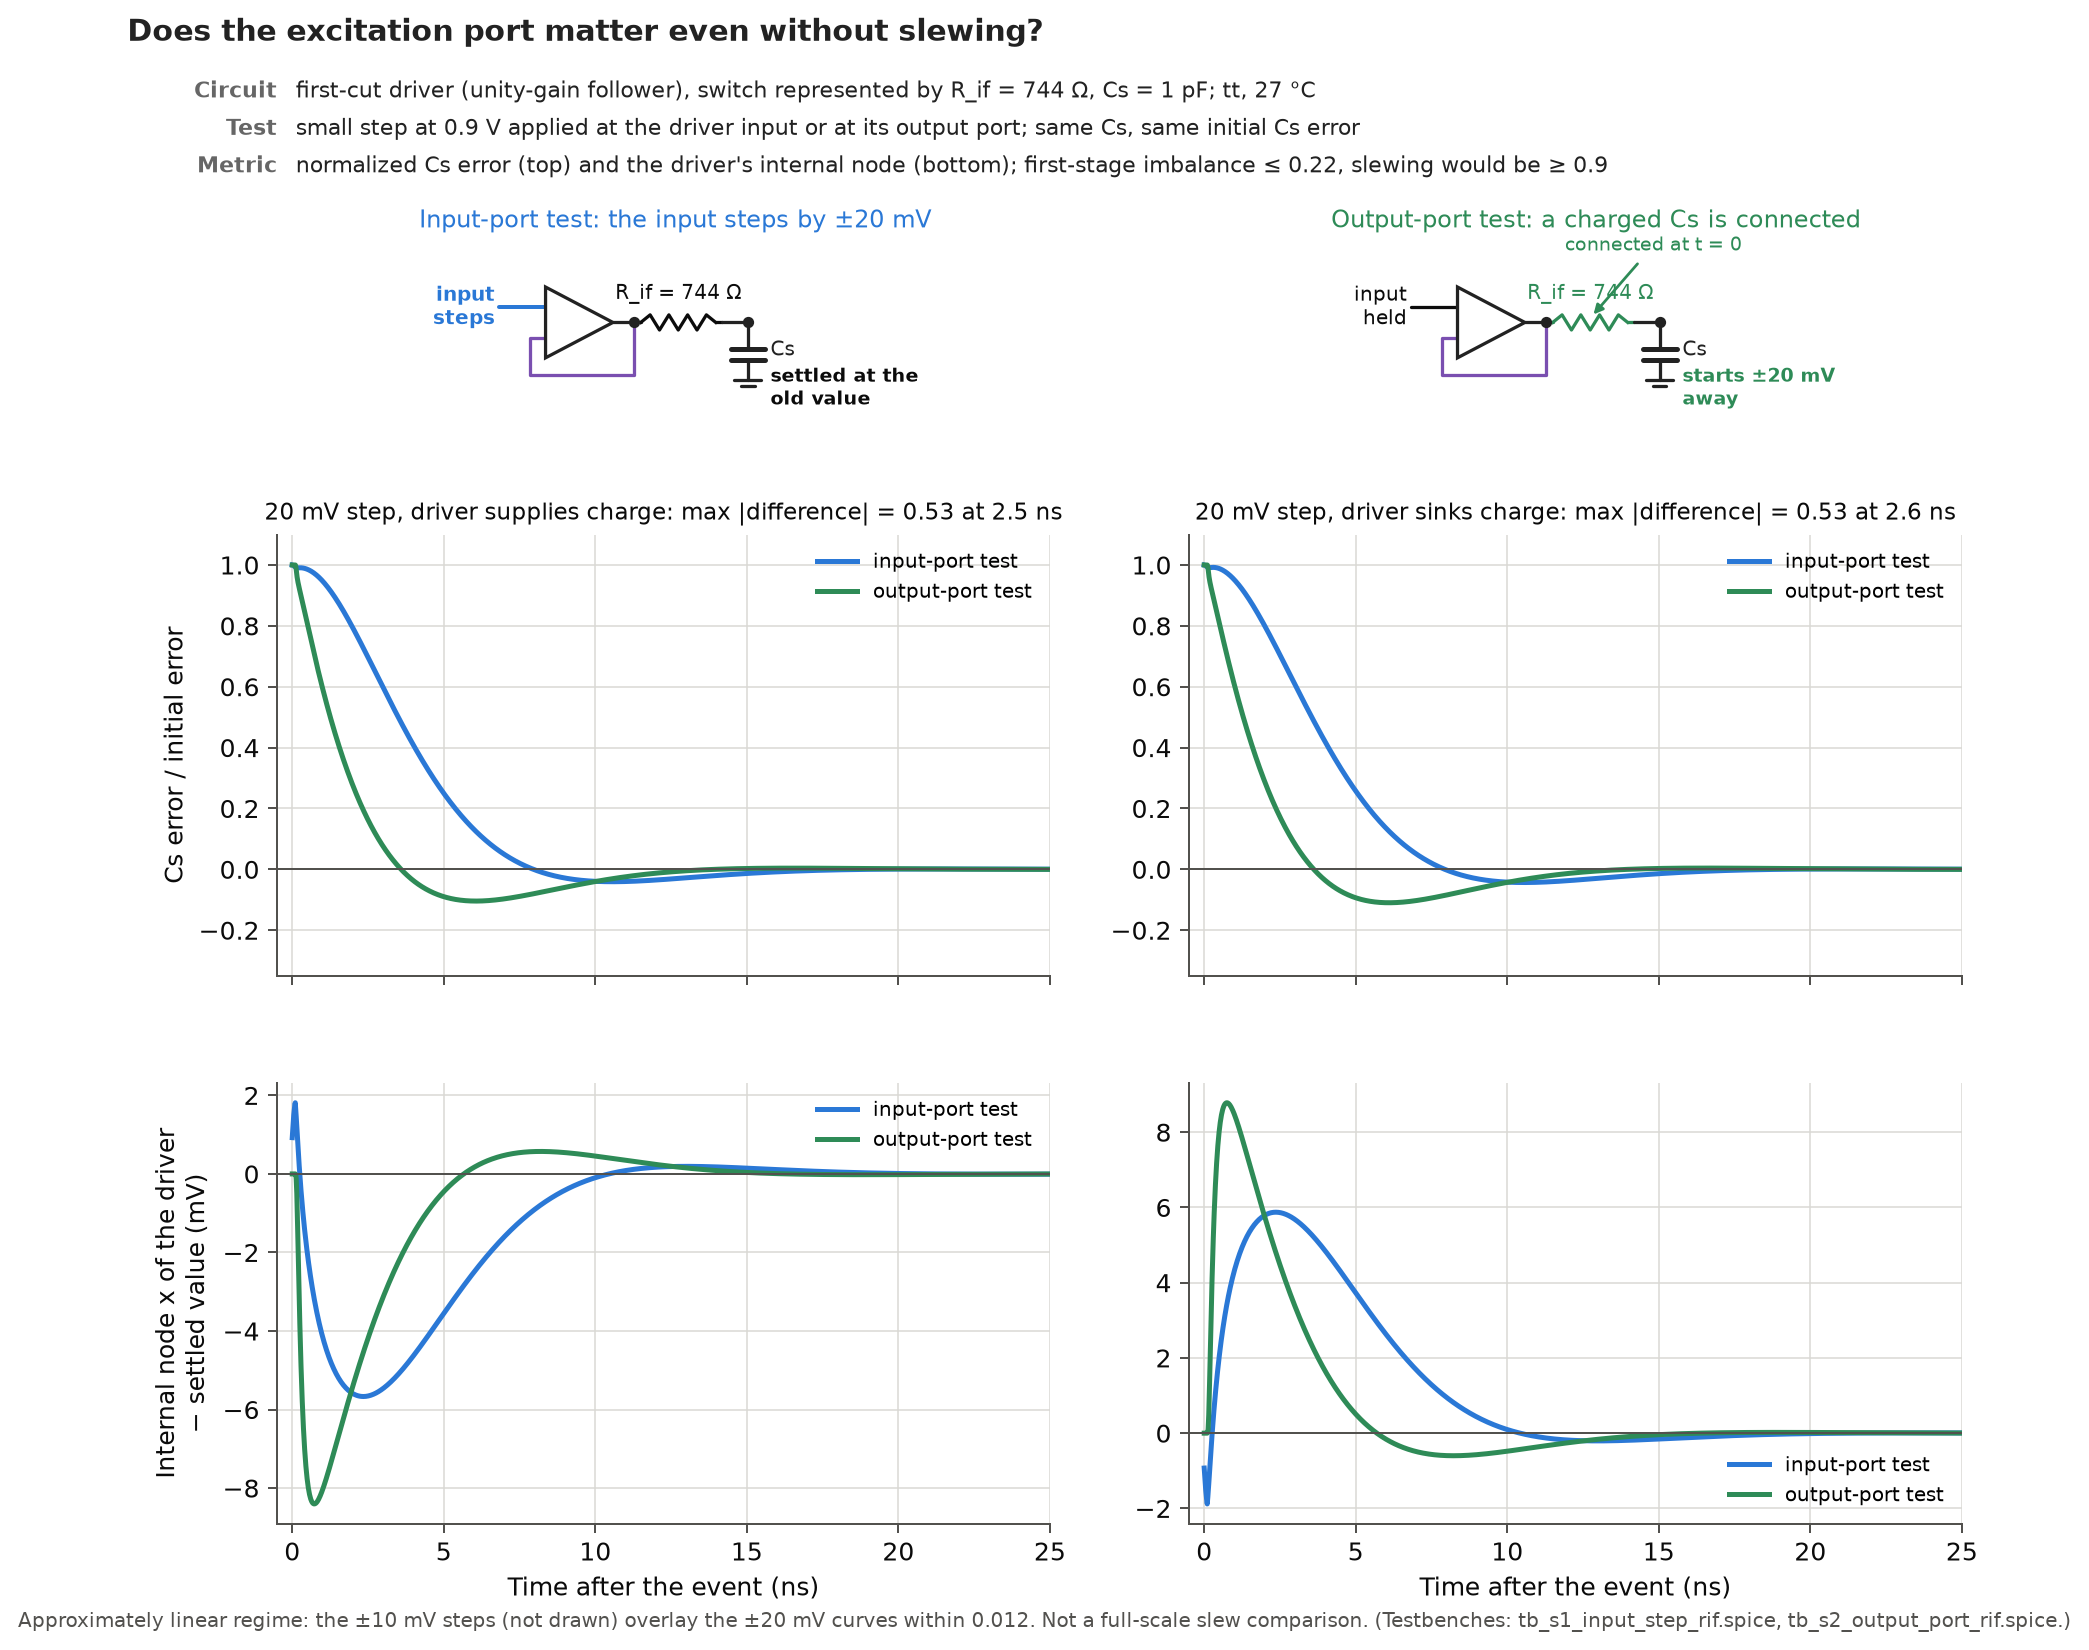

In [11]:
show("figure_sky130_small_step_ports")

*Figure 7. The same driver, `R_if`, and `Cs` excited at two ports by a small step (top sketches): a step is applied
at the driver input, or a charged `Cs` is connected at its output. Same closed-loop poles, different responses, in
the approximately linear regime; this is not a full-scale slew comparison.*

**What the final measurement counts.** The sequential bench runs full-scale alternation for accumulation, every
(previous, target) pair on a 0.1 V grid, a 50 mV staircase in both directions, and a three-level sequence containing
every combination of the two preceding samples.  The held
value is read in the two windows of Section 2, so droop and coupling of the next input level are included. The residual is the corrected held voltage minus the corresponding input level. At
each PVT condition and for each read window, an offset and a gain error are taken from repeated samples at 0.6 V
and 1.2 V and removed by a terminal two-point line, by analogy with terminal-based gain and offset in ADC testing
(IEEE, 2011); the same line is applied to every sequence and previous state at that condition. The first
cycle after start-up is excluded. The design passes if the largest residual magnitude over all counted cycles,
both windows, and every condition of the declared set is at most `VLSB`. Calibrating once at nominal instead would
turn the offset and gain drift over PVT (an offset of about −3.1 to −6.9 mV over the declared set for the selected design) into error. 

For diagnosis, the measurement splits the corrected residual into three measured components: `r_S` immediately
before opening, `r_P` for the increase from pre-opening to early hold, and `r_H` for the increase from early to late
hold (the read times of Figure 2). Thus the early- and late-window residuals are `r_E = r_S + r_P` and
`r_L = r_S + r_P + r_H`. There is no separately measured acquisition or history component: acquisition and history
remaining before opening are included in `r_S`, and history dependence is additionally diagnosed by the spread of
`r_S` across previous states. Coupling of the next input level before the early window is included in `r_P`, which is
therefore broader than the isolated step at opening of Section 3.4. These three measured components are not the four working
allocations of Table 2; the table's last column shows where each allocated mechanism appears in them.

Because the dominant mechanisms have their worst cases at different corners (Section 3.2), and because process
corners represent global (die-to-die) variation and say nothing about mismatch (McConaghy et al., 2013),
the final PVT set is not pruned: five process corners × three supplies × three temperatures, each with all four
sequences, at 1.60, 1.80, and 1.95 V, matching SkyWater's 1.8 V model-validity limit and standard-cell characterisation
supplies (SkyWater Technology Foundry and Google, 2020) (Appendix B). Sensitivity runs at nominal and the worst conditions vary the clock edges (0.1 and 0.5 ns), the skew between the two clock phases (±50 ps), the bias reference (±20 %), and `Cs` (±10 %). 

Five further checks decide whether a pass is credible enough to freeze. **Numerics:** with the bootstrapped
candidate, a 10 ps maximum step and `reltol` = 1e-4 produced 0.1–0.14 mV jumps between neighbouring levels at cold
corners, comparable to the effect being measured, so every closure run uses 5 ps and 1e-5 (Vogt et al., 2024); the worst condition is rerun with a 2 ps step and tighter tolerances, and with Gear instead of trapezoidal integration. A condition whose margin is smaller
than the numerical change is unresolved, not a pass.

**Stability** requires phase margin ≥ 45° and gain margin ≥ 10 dB under both the acquisition load (switch on,
`Cs`) and the hold load (switch off), no ringing above 0.1 `VLSB` in either read window, and, as a design target,
at least 50 mV from the triode edge (`vds − vdsat`) for every driver transistor that is not diode-connected; a
smaller corner margin is accepted only if the device stays saturated, the mechanism is understood, and its
contribution to the parent residual stays small.

**Noise:** the variance of one held sample equals the variance of the track-mode voltage on `Cs` when the switch
opens *(Established)* (Carusone et al., 2012), so the track-mode noise is integrated from 1 mHz (standing
in for a calibration interval) to 50 GHz. The SKY130 model gives only about 0.81–0.83 `kT/C` for the switch at zero
drain-source voltage, where a passive conductance must give exactly `kT/C`, so the switch's model contribution,
measured with a noiseless driver, is replaced by `kT/C`: a conservative `kT/C` floor correction, not an exact
decomposition of the noise sources. A result within 3 µV of the limit is unresolved.

**Model validity:** a transistor-level result is evidence only where the compact models are used inside their
documented validity domain. Each switch transistor is checked against the published SPICE-model domain of its device class
(SkyWater gives, for example, 1.95 V for the 1.8 V devices and 3.3 V for the 3.3 V native NMOS): its gate-source,
gate-drain, and drain-source voltages at the end of each clock phase, and its body-source voltage in both directions
at every instant, at all 1.95 V and all 125 °C conditions, both input timings, and 0.1 ns edges; transient peaks of the
other voltages are reported (SkyWater Technology Foundry and Google, 2020). As first implemented, the body-source check covered only the
reverse direction. Completing it, without changing the criterion, failed the bootstrapped switch then selected:
forward body-source bias up to +0.465 V against +0.3 V, in every run. The investigation that followed found its
transient terminal voltages, until then reported only as a limitation, outside the documented model-validity range of its 1.8 V devices at
every verified condition, nominal included (gate-source voltage up to 2.41 V against 1.95 V). In that region the
simulator extrapolates its models; it is not evidence of breakdown, and no oxide or hot-carrier reliability was
evaluated for either switch. The design was revised (Section 3.4). 

**No cancellation:** the certificate uses `M = max|r_S| + max|r_P| + max|r_H|` at each condition. The maxima may
occur on different samples, so `M` bounds the paired quantity
`Q = max_k(|r_S[k]| + |r_P[k]| + |r_H[k]|)`, with `Q <= M`. If `M <= VLSB`, a PASS does not rely on cancellation.
If `M > VLSB`, paired/pointwise analysis is required before cancellation reliance can be concluded. If that analysis
establishes reliance, the sign relationship must be checked over all 45 conditions, with clock-edge sensitivity and
mismatch analysis added.

The selected design, the scaled driver with the native NMOS switch, was then run through the declared final
closure set, which decides PASS/FAIL: the parent metric over 5,490 counted samples, 45
conditions, and four sequences, with the no-cancellation certificate; driver stability, saturation, and ringing;
sampled noise; and the model-validity checks. The 25 mV level staircase, the sensitivity runs, and the finer numerics
had been declared with pass criteria; before the first final result they were made supporting checks that would not
block a result if they could not be completed in time (Appendix B). For this design the staircase, all sensitivity
runs, and the numerical rerun of the worst parent condition were completed and are judged by their original
criteria, so a failure would still block. The coincident-step case is reported only.
Table 3 gives the role of each row; Figure 8 shows the closure quantities per condition.

In [12]:
# role: closure rows decide PASS/FAIL; supporting rows have a declared
# criterion and were completed; diagnostic rows are reported only
ROLE = {"closure": "closure", "supporting": "supporting, completed",
        "diagnostic": "diagnostic, reported"}
# reader-facing names for two timing labels of the saved result file
WORDS = (("primary timing", "parent input timing"),
         ("STRESS timing (full-scale input step at switch closure)",
          "full-scale input step coincident with switch closure"),
         (" primary)", " parent input timing)"))
rows = ["| role | check | declared criterion | result | verdict |",
        "|---|---|---|---|---|"]
for role in ROLE:
    for c in final["checks"]:
        if c["role"] != role:
            continue
        cells = [ROLE[role]]
        for key in ("check", "criterion", "result", "verdict"):
            text = str(c[key])
            for old, new in WORDS:
                text = text.replace(old, new)
            cells.append(text.replace("|", r"\|"))
        rows.append("| " + " | ".join(cells) + " |")
display(Markdown("\n".join(rows)))
print("final PASS:", final["final_pass"])

| role | check | declared criterion | result | verdict |
|---|---|---|---|---|
| closure | parent residual, parent input timing, 45 conditions × 4 sequences (5490 counted samples), early and late windows | max\|r\| ≤ 1 LSB | 0.319 LSB at fs_1.60V_+125C | PASS |
| closure | driver loop, 135 condition/level points, acquisition and hold loads | PM ≥ 45°, GM ≥ 10 dB | PM ≥ 66.5°, GM ≥ 14.4 dB | PASS |
| closure | driver saturation margins vds − vdsat (all non-diode-connected devices) | design target ≥ 50 mV; bounded worst-corner reduction allowed if still saturated | min 31 mV (xm2, sf_1.60V_+125C, 1.2 V); 2 point(s) below 50 mV — input pair at the top of the range, 1.60 V supply; still saturated | PASS (bounded corner reduction) |
| closure | ringing in the read windows (peak-to-peak) | ≤ 0.1 LSB | 0.014 LSB | PASS |
| closure | sampled noise, 90 condition/level points (switch at the kT/C floor, 1 mHz–50 GHz) | ≤ 146 µV rms (unresolved within 3 µV) | 130.2 µV (0.222 LSB) at sf_1.60V_+125C, 0.6 V | PASS |
| closure | no-cancellation certificate (M = sum of component maxima) | M ≤ 1 LSB; otherwise paired/pointwise analysis required | max M 0.377 LSB; certified at every condition | PASS |
| closure | switch terminal voltages, steady (end of each clock phase) | \|VGS\|,\|VGD\|,\|VDS\| ≤ each device's model-domain limit (1.8 V devices 1.95 V) (model validity) | max 1.353 V of 3.30 V (MS vgs, ss_1.95V_-40C) | PASS |
| closure | switch NMOS body-source voltage, reverse | within each device's model range (1.8 V devices ≥ −1.95 V) | min -1.211 V (MS) | PASS |
| closure | switch MOS body-source voltage, forward (all instants) | within each device class's documented body-source model-validity range (3.3 V native NMOS ≤ +0.0 V) (A3) | max -0.575 V vs +0.0 V (MS, ss_1.95V_-40C parent input timing); 0.000 ns/cycle beyond the limit | PASS |
| supporting, completed | 25 mV levels at 4 conditions | max\|r\| ≤ 1 LSB | 0.319 LSB at fs_1.60V_+125C | PASS |
| supporting, completed | sensitivities: edges 0.1/0.5 ns, φ/φ̄ skew ±50 ps, Iref ±20 %, Cs ±10 % | max\|r\| ≤ 1 LSB | 0.482 LSB (iref_-20%, fs_1.60V_+125C) | PASS |
| supporting, completed | numerics at fs_1.60V_+125C (cal_alt): tmax 2 ps/reltol 1e-6; gear | \|Δ\| ≤ 0.02 mV and margin > \|Δ\| | Δ +0.003 / -0.006 µV; margin 0.399 mV | PASS |
| diagnostic, reported | full-scale input step coincident with switch closure | diagnostic | 2.8–22.2 LSB (fs_1.60V_+125C worst) | reported |
| diagnostic, reported | switch terminal voltages, transient (all instants) | reported (A8); each device against its published SPICE-model domain | peak 1.37 V of 3.30 V (MS vgs, ss_1.95V_-40C); inside the domain at every instant | reported |

final PASS: True


*Table 3. Final verification of the selected design against criteria declared before its result was assembled.
Closure rows decide PASS/FAIL; supporting rows were completed and meet the criteria declared for them; diagnostic rows
are reported, not pass/fail items.*

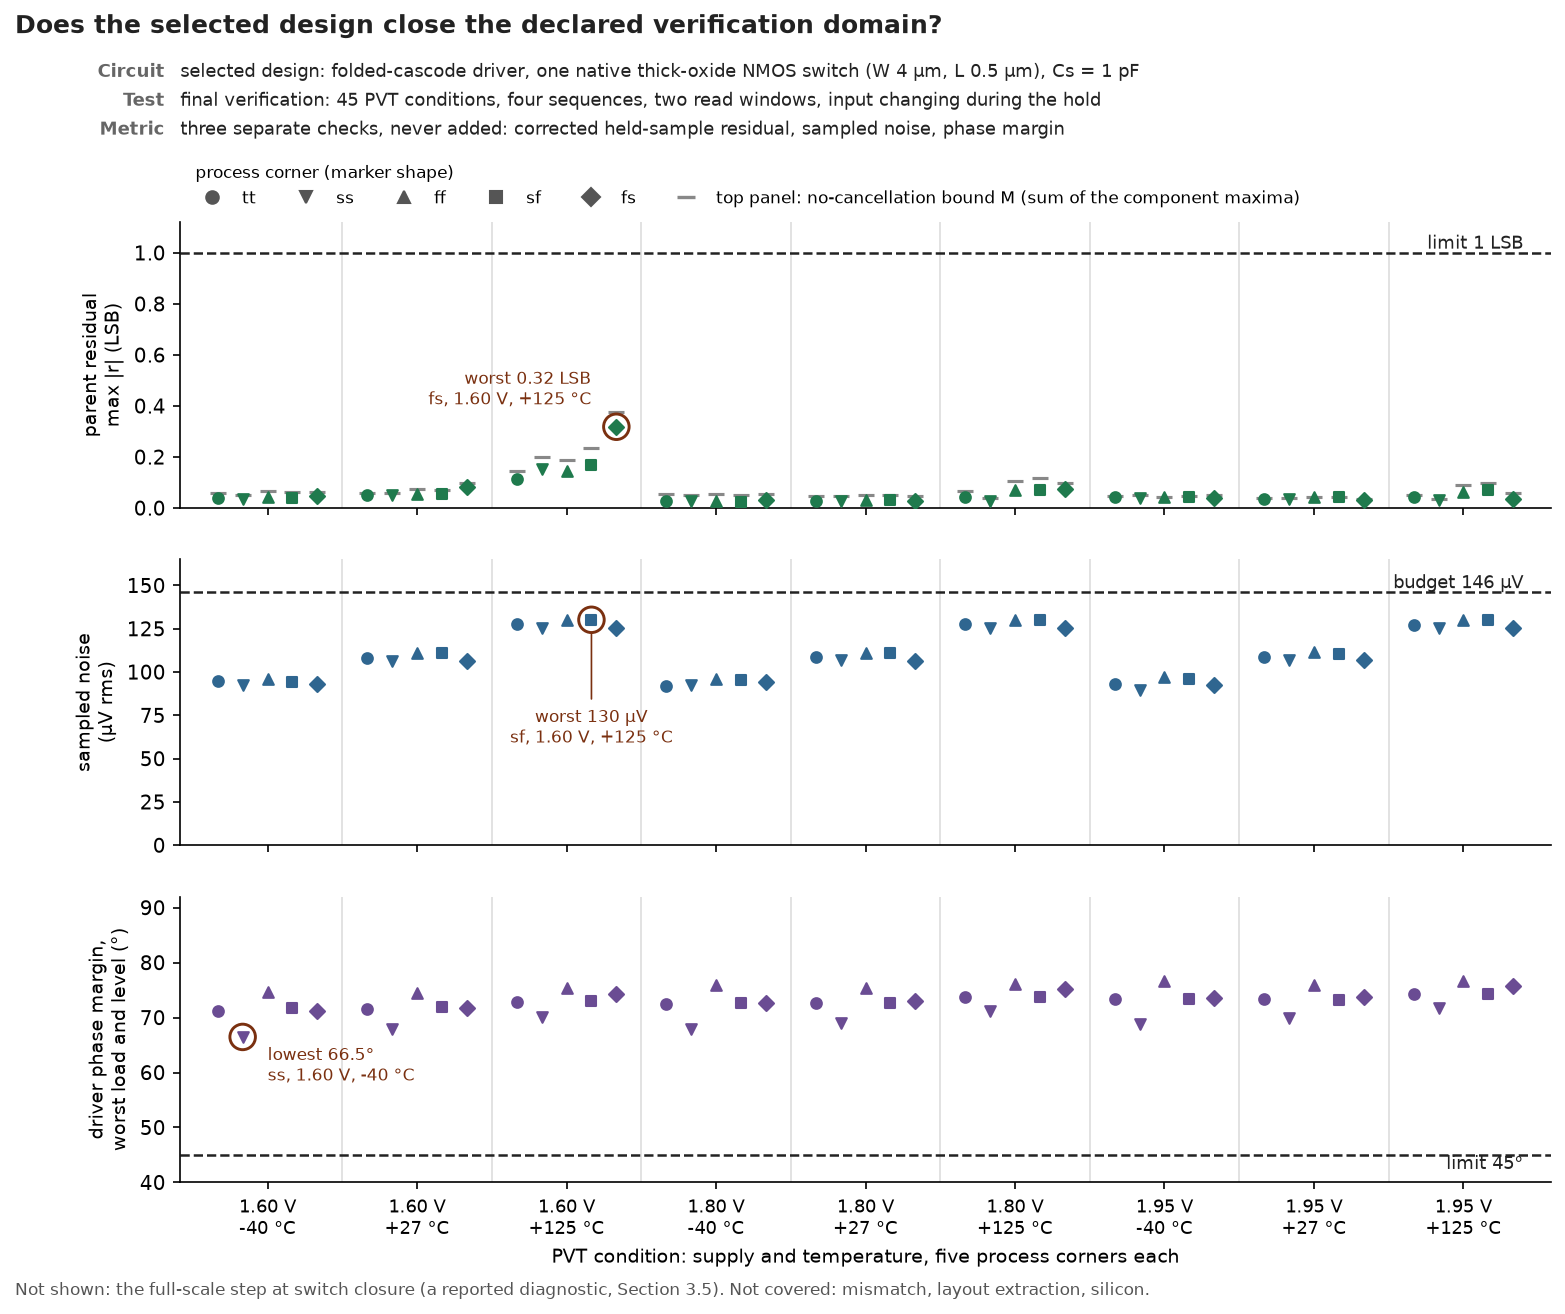

In [13]:
show("figure_closure_matrix")

*Figure 8. The selected design at each of the 45 conditions, one panel per quantity and limit: largest parent
residual (grey bars: the no-cancellation bound `M`), largest sampled noise of the two input levels, and the smallest
driver phase margin over three input levels and both loads. The worst condition of each panel is circled.*

The worst parent residual is 0.32 `VLSB` at fs_1.60V_+125C, where acquisition through the native switch is
slowest; the no-cancellation bound `M` stays below 0.38 `VLSB` at every condition, so no pass relies on
cancellation. Rerunning the worst condition with a 2 ps step and tighter tolerances, and with Gear integration, changes the worst residual by less than 0.01 µV. Levels on a 25 mV grid at the worst conditions give at most 0.32 `VLSB`. Clock edges of 0.1 and 0.5 ns, ±50 ps phase skew, ±20 % bias current, and ±10 % `Cs` move the worst residual to at most 0.48 `VLSB`. In the model-validity runs every switch voltage stays inside the
documented domain at every instant: at most 1.37 V on a 3.3 V-class device, and the body-source junction is always reverse-biased
(at most −0.575 V). The full-scale input step at switch closure, a diagnostic, gives 2.8–22.2
`VLSB`: with the larger `Cc` that the noise budget required, the driver does not settle such a step
within 40 ns, and the native switch's on-resistance makes it worse at hot, low supply than with the bootstrapped
switch (Section 3.4).

On that evidence the design is frozen: it closes the declared deterministic requirement and the random-noise
budget, with a stable driver and every switch device inside its documented model-validity domain, over the declared
schematic-level verification domain. This is not production sign-off; mismatch, layout parasitics, and silicon are
outside that domain (Appendix C).

Each rung was used for the decision it could support: the reduced model to show why two excitations differ, the
transistor-level test to show that the difference matters in this driver, the sequential bench to find a history
effect that a precharged fixture cannot show, the PVT matrix to find where each mechanism is worst, and the freeze
checks to decide whether the pass could be trusted — one of which showed that an earlier pass rested on model
extrapolation. Sufficient evidence is defined by the decision and the claim
being made, not by the most detailed model available, and stating what the evidence does not cover is part of the
result.

### 3.6 Keep the loop closed across boundaries

Engineers divide a coupled circuit into blocks so that not every variable has to be solved at once, so that
different people can work in parallel, and so that blocks can be reused in other products. The decomposition makes
the design tractable, but the physics does not stop at the boundary. A block's result holds under conditions that
circuits on the other side of the boundary supply — the load it drives, the timing of its inputs, the supply it
shares, the calibration that follows it. When a result depends on a condition supplied elsewhere, someone has to know
where that condition is written down, who checks it in the connected circuit, and what happens when the block is
integrated differently or reused.

A boundary therefore creates obligations: a representation of the neighbour adequate for the decisions made against
it (Section 3.3); applicability conditions — load, timing, range, supply, calibration — recorded where the integrator
will see them; a connected test for whatever the representation omits; reassessment on reuse, as reuse and
systems-engineering practice require for heritage items in a new environment (Keating and Bricaud, 2002; NASA, 2016); and a named owner for each check in the verification plan, because an assumption that lives
only in one designer's testbench has not crossed the interface (Kundert et al., 2000; Kundert, 2003). Where to draw the boundary is itself a design choice, with the trade-offs the running example
shows.

Figure 9 shows three places to draw the boundary in the running example. In scope A, driver, switch, and `Cs` are
one problem: switch width, driver current, and clock can be chosen against the parent residual at once, but the
driver cannot be reused or verified without this switch. In scope B, the boundary sits before the switch: the
driver can be characterized and reused on its own, provided the representation of the sampling network carries
every switch property that matters. The first cut's `R_if` and 1 kΩ allocation came from scope B, and both problems
found there — a representation without the turn-on event, and an allocation that sized the switch for settling
alone — concern what crossed that boundary. In scope C, the switch is inside the driver's block; the turn-on event
becomes internal, and any change of switch requires a new characterization of the whole block.

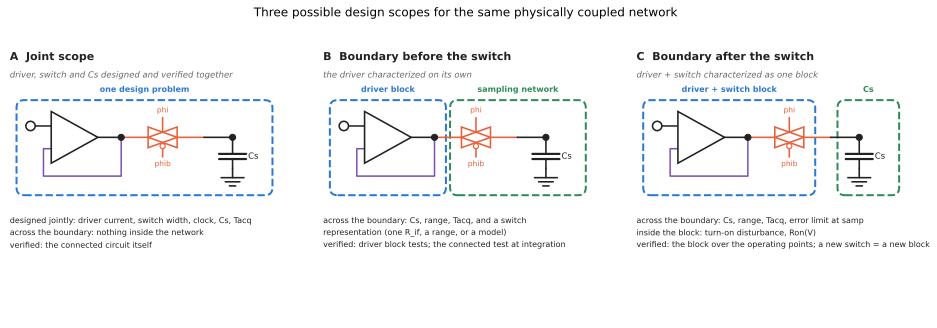

In [14]:
diagram("design_scopes")

*Figure 9. Three design scopes for the same network. A: joint; B: boundary before the switch, with an interface
representation of the sampling network; C: boundary after the switch. They differ in search size, interface content,
reuse, independent characterization, and who verifies the connection.*

The selected design is verified only under the conditions of Table 4, and they must travel with it.

| Condition the closure depends on | Declared verification range |
|---|---|
| sampling capacitance | `Cs` = 1 pF; ±10 % verified |
| clock | complementary phases, 0.2 ns edges; 0.1–0.5 ns edges and ±50 ps phase skew verified |
| timing | 100 ns period, 40 ns acquisition, 60 ns hold |
| input timing | input changes during the hold (1 ns after opening); a full-scale input step coincident with switch closure is reported as a diagnostic only: 2.8–22.2 `VLSB`, not supported |
| supply and temperature | grid of 1.60, 1.80, 1.95 V × −40, 27, 125 °C × five process corners |
| calibration | two-point offset/gain correction determined at each operating condition and separately for each read window, from repeated samples at 0.6 V and 1.2 V |
| read time | early window 10–20 ns after opening; late window up to 1 ns before the next acquisition |
| bias reference | 10 µA; ±20 % verified |
| random noise | 130 µV rms worst against 146 µV (0.25 `VLSB` rms) |
| not covered | mismatch, layout extraction, transistor-level clock drivers; ideal supply and ground, bias reference, and passives; substrate coupling into the switch, whose body is the substrate |

*Table 4. What travels with the block: the declared conditions of the final verification; results in Section 3.5.*


Each row is an obligation for whoever integrates the block. A downstream circuit that reads the sample later than
the late window, a calibration done once at nominal, or an input step coincident with switch closure puts the block
outside its verified conditions. Reuse with a different switch is a new composition: with the native switch the
worst residual is set by acquisition at hot, low supply, so the driver's settling result does not carry over
unchanged to another switch; even with this switch, 20 % less bias current or 10 % more `Cs` raises the worst
residual from 0.32 to 0.48 or 0.39 `VLSB`. In each
case the obligation is a named test — the sequential bench at the affected conditions — not a general instruction to
be careful.

Organization research relates an organization's communication structure to the structure of the systems it
designs, and empirical work finds such mirroring in product and software development (Conway, 1968; MacCormack et al., 2012). In analog work this suggests *(Reflection)* that circuit, IP, and team
boundaries can shape one another whether or not the electrical coupling is weak there: under scope B the driver and
switch owners can both have correct results, and the connected test belongs to neither unless the plan assigns it.

## 4. What changes when AI enters the loop?

Sections 1–3 separate why analog design is difficult from the practices that make it tractable. AI raises a
separate question for each.

### 4.1 Does AI change why analog design is difficult?

Mostly not. The sources of the difficulty in Section 1 are physical. MOS devices are nonlinear, so their small-signal
parameters and the strength of every interaction move with operating point, signal level, and PVT. Impedance,
current, and headroom are finite, so one stage loads another and a loop slows or rings when its load changes. Noise
is set by devices, temperature, and bandwidth. Parasitics add poles and coupling paths. Stored charge carries one
operation's result into the next. Process, supply, and temperature vary, and models still omit effects that only
appear at a lower level of description or in silicon. None of this depends on who, or what, is running the design
loop.

The running example shows the same thing at circuit level. The transmission gate's conduction gap at cold, low
supply, the driver's tail leaving saturation at a 0.6 V input, and the previous-sample dependence of the first
bootstrapped variant (Sections 3.2 and 3.3) are properties of the circuit. An AI system that sizes this circuit faces
the same coupled network as Figure 1.

The need for evidence does not disappear either. A tool that proposes a design produces a claim, and the claim
is only as good as the verification behind it. Agent-based analog design work has reported agents declaring passes
that were false, for example for a SKY130 SAR ADC carried through post-extraction checks
(Yoshioka, 2026) (preprint).

### 4.2 Does AI change how engineers make the difficulty tractable?

Some difficulty comes from physics; some comes from the cost of handling coupled quantities together: the number
of conditions a person can simulate, read, and understand in a day; the number of knobs a person can move
jointly; the cost of a circuit revision; the cost of coordinating the people who own the driver, the switch, and the
verification. Allocations, interface representations, and block boundaries exist partly because of that cost
(Section 3.6). In this design the 1 kΩ on-resistance allocation and the `R_if` representation let the driver and the
switch be designed separately, and both later proved inadequate for a decision they were used for (Sections 3.3 and
3.4). *(Interpretation.)*

Current peer-reviewed tools automate bounded parts of the loop: op-amp design on a defined benchmark with a
domain-specific language model (Chen et al., 2024), PVT-aware sizing with model-based reinforcement learning
that keeps corners inside the optimisation loop (Ahmadzadeh et al., 2026), multi-agent analysis and design
with tool use (Shen et al., 2026), and interactive layout through tool calls (Liu et al., 2025).
*(Established for those tasks; nothing more general is claimed.)*

*(Reflection from here to the end of 4.2.)* AI may greatly reduce the cost of search, simulation, implementation,
diagnosis, verification, and coordination. If it makes a larger coupled region cheap to design, search, and verify
jointly, some boundaries that exist mainly for human tractability can move. In this circuit, driver compensation,
switch structure, `Cs`, clock sequence, and the sequential verification could be one search rather than three owners
connected by allocations — scope A of Figure 9 rather than scope B. The allocation split of Section 3.1 would then
matter less as a division of work and more as a diagnostic. Which decompositions are worth keeping would be decided
again, block by block, as these costs change.

Other boundaries exist for reasons that do not depend on search cost, and they are likely to stay:

- **independent verification**: a result checked by a different tool, model, or person than the one that produced it —
  the reported false passes make this concrete, and here the sequential bench found a previous-sample error that a
  precharged fixture cannot show by construction;
- **reuse**: a block with a stable interface that serves several products, carrying conditions such as those of
  Table 4;
- **physical isolation**: between a noisy domain and a sensitive input, or between supplies;
- **measurement access**: a boundary at a node that can be probed on silicon;
- **fault containment** and **responsibility**: someone must answer for a requirement.

### 4.3 Search works inside a formulation

Section 3 contains three concrete cases. The width ladder ranked the narrowest gate first by the local allocation for the step at opening and below the half- and
quarter-width gates by the parent residual; at cold, low-supply corners the transmission gate stopped conducting at
full and half width, so a narrower gate cannot conduct there either (Derived). A search given the `R_if`
representation as its model would have accepted 0.8 ns of acquisition in the zero-step case where the connected
circuit needs 10.3 ns (Section 3.3). And a search given only the nominal corner as its verification domain would
have kept the half-width gate, whose residual at `ss`, −40 °C, 1.62 V was 296 `VLSB` (Section 3.4). In each case,
more search against the same objective, model, or domain does not resolve the conflict. *(Interpretation of Observed
results.)*

The objective is only one of the things a search is given. It is also given a set of variables (here, switch width),
a space of circuits (a transmission gate of some width), a partition into blocks (a driver designed against a model
of the switch), a model, an operating domain, and a verification plan. Closure in this example required changing
several of these — the circuits of the switch and of the driver, the allocation, and the verification, which moved
from a precharged fixture and an `R_if` block test to connected sequential benches over 45 PVT conditions, with the
input-timing condition of the verification domain made explicit. The parent function and its ±1 `VLSB` residual
criterion, input range, acquisition interval, and PVT set stayed fixed (Sections 3.1 and 3.4). Allowing a search to change
its objective, variables, model, or verification plan is not enough by itself: the process also needs a check that
shows when the current choice of them no longer serves the parent requirement. Here that evidence came from
evaluating the parent residual on the connected circuit, with the held state carried from one sample to the next,
over the declared operating conditions.

*(Reflection from here to the end of Section 4.)* Stating the parent requirement, choosing the conditions over which it must hold, choosing which variables and
circuit structures are open, deciding what is designed jointly, deciding which representation is adequate for which
decision, planning verification, diagnosing a failure, noticing when a pass depends on a cancellation, and judging
when the evidence is enough to freeze are themselves tasks that AI systems may increasingly take on. Nothing here
argues that these judgments are inherently human. What the eventual division of work between people and AI will be,
as development processes are rebuilt around AI, is not known.

If AI systems do come to revise the formulation as well as search within it, the need to understand the formulation
grows rather than shrinks, because the person who directs or checks that work must know what each part of it is for.
An allocation, a model, a test, a boundary, or a review each exists to control a particular physical or design
difficulty, and each introduces an assumption. An engineer who knows both can tell when to direct the work, check it,
or rely on it, whoever or whatever performs it. Section 5 lists those skills.

## 5. What an analog designer needs to learn

Circuit theory is necessary, and every step of this notebook used it. What the equations do not supply is the
engineering layer around them: how to state a problem that is not yet complete, how to reason about quantities that
are physically coupled and whose coupling changes with the conditions of use, which representation to trust for which
decision, at which level to respond when a result fails, and when the evidence is enough. A junior designer learns
the equations from textbooks; the following skills are usually learned by carrying a real block through design,
integration, verification, and revision.

| Skill | Where it appeared |
|---|---|
| Formulate an incomplete problem without pretending it is final, and know the role each quantity plays in it and what evidence may revise it | 3.1 |
| Relate local decisions to the parent result: one knob moves several quantities, which reach the parent residual as a signed sum, so a local metric can pass, or rank designs, differently | 1, 3.2, 3.4 |
| Characterize where a result holds, over operating point, previous state, timing, and PVT, rather than quoting one number | 3.2 |
| Choose a model or test that is adequate for the decision at hand, and notice when it is not | 3.3, 3.5 |
| Revise at the level the evidence points to, including changing the circuit so that a dependency weakens instead of retuning a value | 3.4 |
| Decide what a search may change — objective, variables, circuit structure, joint scope, model, conditions — and recognize when the formulation itself is the problem | 1, 3.4, 4.3 |
| Judge when evidence is sufficient to freeze a design, and say what it does not cover | 3.5 |
| Keep the obligations a boundary creates attached to the block when it is reused or integrated | 3.6 |

None of these replaces knowing how a circuit works; each is a way of using that knowledge on a problem whose
requirements are provisional and whose physics is coupled. As AI systems take over more of the search,
simulation, sizing, layout, and possibly the judgments themselves, these skills are what let an engineer decide
— or check how a tool decided — what problem to solve, which results need independent checking, and when a pass
is enough. Whatever tools are used, the designer must understand the problem being solved and why the evidence
for the answer can be trusted.

## Appendix

### A. Reproducing and rerunning

Everything in this notebook is regenerated with open-source tools. Tested versions: ngspice-42; SKY130A from
open_pdks commit `c6d73a35f524070e85faff4a6a9eef49553ebc2b` (installed with volare); Python 3.14.6 with the
packages pinned in `uv.lock` (uv project; Python ≥ 3.12 required).

```bash
uv sync --locked                        # Python environment from pyproject.toml + uv.lock
export PDK_ROOT=$HOME/.volare           # location of sky130A (e.g. installed with volare)
uv run python scripts/reproduce.py --no-spice    # figures and notebook from the committed results (minutes)
uv run python scripts/reproduce.py --skip-final  # all simulations except the final closure verification
uv run python scripts/reproduce.py               # everything, including the final closure verification
```

| Result | Script | Outputs |
|---|---|---|
| first-cut evidence (Figures 5–7; Sections 3.2–3.5) | `experiments/experiment_a/sky130/run_sky130.py`, `run_followup.py`; reduced model `experiments/experiment_a/ideal/run_experiment.py` | `results/data/`, `results/figures/figure_sky130_*`, `figure_reduced_model_*` |
| first cut on the sequential bench (Figure 4) | `experiments/closure/run_screen.py f2 --pvt screen --legacy` (screening definitions before the final-verification amendments) | `results/closure/screen/f2_screen.json` |
| screening records quoted in Section 3.4: half-width first-cut gate, native-switch width screen | `experiments/closure/run_screen.py f2_half --pvt screen --legacy`; the width screen is a saved record (one, two, four fingers at three conditions) | `results/closure/screen/f2_half_screen.json`, `results/closure/redesign/q1_nvt{1,2,4}_n3.json` |
| final closure verification of the selected design (Section 3.5, Figure 8) | `experiments/closure/run_final.py q1_nvt1`, then `assemble_final.py` (the selected design is `SELECTED` in `designs.py`) | `results/closure/final/q1_nvt1/*.json`, `results/figures/figure_closure_matrix.*` |
| explanatory diagrams (Figures 1–3, 9) | `scripts/draw_restart_diagrams.py` (Figures 1–3), `scripts/draw_diagrams.py` (Figure 9) | `assets/diagrams/*.svg` |

The two "Try it" cells read `results/data/sky130_waveforms_tt.csv` and `results/data/sky130_followup_summary.json`;
with `SOURCE = "spice"` they rerun only their first-cut benches through
`experiments/experiment_a/sky130/interactive.py`, writing to a temporary folder. The cell below re-simulates one
nominal case of the selected design on the sequential bench.

In [15]:
# Optional: re-simulate one nominal case of the selected design on the
# sequential bench (requires ngspice and SKY130A; a few minutes).
# Set RUN_SPICE = True here, or execute the notebook with the environment
# variable RUN_SPICE=1. Edit the design in experiments/closure/designs.py
# (or pass another PVT) to see the parent residual move.
RUN_SPICE = os.environ.get("RUN_SPICE", "0") == "1"
if RUN_SPICE:
    sys.path.insert(0, str(REPO / "experiments" / "closure"))
    import designs
    import parent_metric as pm
    import shbench as sb
    r = pm.evaluate_many(designs.DESIGNS[designs.SELECTED],
                         [sb.PVT("tt", 1.80, 27)],
                         include=("cal_alt", "pair"))[0]
    print(f"{r['tag']}, cal_alt + pair: "
          f"max|r| = {r['max_abs_r_LSB']:.3f} LSB, "
          f"supply current {r['supply_current_uA']:.0f} µA")
else:
    print("skipped: set RUN_SPICE = True to re-simulate one nominal case "
          "(requires ngspice and SKY130A)")

skipped: set RUN_SPICE = True to re-simulate one nominal case (requires ngspice and SKY130A)


The pre-registered parent metric, budget, verification sets, and every amendment made before final verification
are in `experiments/closure/CLOSURE_BRIEF.md`; the sequential bench is `experiments/closure/shbench.py`, the metric
`parent_metric.py`, and the stability, noise, and model-validity checks `stability.py`, `noise.py`, and `run_final.py`;
the documented model-validity domain of each device class is listed in `bootstrap_domain.py`, which also holds the
terminal-voltage diagnostics of the bootstrapped switch. The superseded bootstrapped design keeps its final result in
`results/closure/final/q1_boot2/` (`final_pass` false after the completed body-source check) for the comparison in
Sections 3.4–3.5.
The first-cut experiment definition is `experiments/experiment_a/sky130/DESIGN_BRIEF.md`.

### B. Supporting design details

The selected design, as summarized from the final result and as simulated:

In [16]:
d = final["design_summary"]
rows = ["| item | value |", "|---|---|"]
rows += [f"| {k} | {v} |" for k, v in d.items()]
display(Markdown("\n".join(rows)))

| item | value |
|---|---|
| driver | folded-cascode first stage (native-threshold NMOS pair), PMOS common-source second stage, Miller Cc + Rz, output capacitor; bias lines RC-filtered |
| sampling switch | native thick-oxide NMOS (sky130_fd_pr__nfet_03v3_nvt, W 4 µm, L 0.5 µm), gate driven directly by the track clock; no bootstrap |
| Cs | 1 pF |
| clock | two complementary phases, 0.2 ns edges, 100 ns period, 40 ns acquisition |
| supply current | 784 µA at tt (max 977 µA over the declared set) |
| devices | driver 22 transistors, switch 1 |
| ideal passives in the driver | CC=5p CF3=2p CF4=2p CF1=2p CF2=2p CO=4p CF5=2p; RZ=0.3k RF3=100k RF4=100k RF1=100k RF2=100k RF5=100k |

In [17]:
# the selected driver and sampling switch as simulated
# (ideal elements are listed in each header)
for f in ("driver_drv_Q1.spice", "sw_nvt.spice"):
    t = (REPO / "experiments" / "closure" / "netlists" / f).read_text()
    print(t[t.index(".subckt"):t.index(".ends") + 5], "\n")
print("selected switch instance parameters "
      "(overriding the defaults above):", final["switch_params"])

.subckt drv_Q1 vcmd fb out ibias vdd vss
* reference (Iref = 10 uA sunk into ibias) and NMOS bias sinks, 10 uA each
XM8  ibias ibias vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=1
XM18 vbp   ibias vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=1
XM21 vbpc  ibias vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=1
* PMOS bias: vbp diode; PMOS copies feeding the vbnc diode and the output-sink diode; vbpc diode
XM17 vbp   vbp   vdd vdd sky130_fd_pr__pfet_01v8_lvt W=20 L=0.5 m=1
XM20 vbnc  vbp   vdd vdd sky130_fd_pr__pfet_01v8_lvt W=20 L=0.5 m=1
XM22 vbnc  vbnc  vss vss sky130_fd_pr__nfet_01v8 W=1 L=2.5 m=1
XM19 vbpc  vbpc  vdd vdd sky130_fd_pr__pfet_01v8_lvt W=1.65 L=1 m=1
XM23 ib2   vbp   vdd vdd sky130_fd_pr__pfet_01v8_lvt W=20 L=0.5 m=1
XM24 ib2   ib2   vss vss sky130_fd_pr__nfet_01v8 W=2.5 L=4 m=1
* tail and native-threshold input pair
XM5  tail  ibt   vss vss sky130_fd_pr__nfet_01v8 W=4 L=1 m=17
XM1  f1    fb    tail vss sky130_fd_pr__nfet_03v3_nvt W=4 L=0.5 m=8
XM2  f2    vcmd  tail vss sky130_fd_p

The driver responses compared before the final refinement (Section 3.4):

| Driver response | Current at `tt` | What it improved | What it cost or missed |
|---|---:|---|---|
| Two-stage, mirror-loaded first stage (first cut) | 130 µA | fast; noise ≈ 263 µV at `tt` | pre-opening residual up to 1.03 mV at the `fs` corners (tail in triode; measured with the first-cut gate) |
| Folded-cascode first stage, native pair, separate sink bias | 288 µA | pre-opening residual ≤ 0.022 mV; screening ≤ 0.27 `VLSB` (parent input timing) and ≤ 0.42 `VLSB` (coincident step) | noise ≈ 745 µV at `tt`* |
| Single-stage, load-compensated, gain-boosted folded cascode | 272 µA | screening ≤ 0.50 `VLSB` in the parent input timing at a third of the selected driver's current | noise 123–234 µV over the screened conditions*, above budget at `tt`; coincident step up to 42.7 `VLSB` |

*Table B.1. Driver responses with the bootstrapped switch (5 µm), `Cs` = 1 pF, 40 ns, on the sequential bench at the
screening conditions of that stage (supplies 1.62/1.80/1.98 V). Noise is rms on `Cs`, budget 146 µV. \*Earlier noise
method (1 kHz lower bound, switch as modelled); the correction of Section 3.5 changes these figures by a few µV.
Source: `results/closure/candidates/table34.json` (`experiments/closure/table34_evidence.py`).*

Three decisions were recorded before final verification. The supplies moved from 1.62 and 1.98 V to 1.60 and
1.95 V, because SkyWater publishes the 1.8 V MOS models as valid up to 1.95 V and characterises its 1.8 V standard
cells at 1.60 V and 1.95 V (SkyWater Technology Foundry and Google, 2020). The coincident-step case, a full-scale input step coincident
with switch closure, moved from the pass/fail set to a reported diagnostic, because the frozen parent function assumes
an input that changes during the hold; the ±1 `VLSB` residual criterion, input range, 40 ns acquisition interval,
and PVT set were not changed. For random noise, one final refinement toward 146 µV was allowed, with a single fallback to `VLSB/√12` ≈
169 µV, the quantization-noise equivalent of a 10-bit step, if it missed; it did not miss. A fourth decision, taken
before the first final result and written into the brief shortly after it (amendment A9), turned the 25 mV staircase,
the sensitivity runs, and the finer numerics, all declared with pass criteria, into supporting checks that need not be
complete for a result; the assembly still applies their original criteria whenever they have been run. For the
selected design the staircase, all 24 sensitivity points, and the numerical rerun of the worst parent condition were
run and pass. Completing the body-source part of the model-validity check was not an
amendment: the criterion was declared before final verification, and only its implementation had been incomplete.


### C. Scope and provenance

The selected design is a defensible point within the explored design space, not a global optimum, and the closure
is schematic-level, not production sign-off. Specifically:

- Device mismatch, layout extraction, aging, package, and silicon are not covered. Mismatch offset is removed by the
  two-point correction, but its effect on the level-dependent residual is not simulated.
- Clock drivers are ideal ramps (the edge and skew sweeps of Section 3.5 stand in for them); the bias reference, the compensation and filter resistors and
  capacitors, the output capacitor, and `Cs` are ideal elements, so PDK resistor and capacitor corners are not
  applied. The noise analysis excludes the bias reference and the clocks.
- The requirement assumes a two-point calibration at each operating condition, and covers the parent input
  timing; a full-scale step at switch closure is a reported diagnostic.
- Switch terminal voltages are checked against the documented compact-model validity domain of the device class, not against
  a reliability rule; no oxide or hot-carrier reliability claim is made. The switch's body is the p-substrate, and
  substrate coupling is not simulated.
- The driver's input-pair saturation margin narrows to 31–33 mV at one condition against the 50 mV design target
  (Section 3.4), with the device still saturated.
- Level coverage is a set of representative grids (0.1 V pairs, 50 mV and 25 mV staircases), not a continuous sweep.

The circuit was designed from scratch for this notebook and does not reproduce any private design. AI-assisted
research, simulation scripting, design exploration, and writing tools were used during development; the author
selected the engineering questions, set and reviewed the requirements and decisions, and is responsible for the
final artifact.

## References

- **Abo and Gray, 1999** — Abo, Andrew M.; Gray, Paul R. (1999). *A 1.5-V, 10-bit, 14.3-MS/s CMOS Pipeline Analog-to-Digital Converter*. IEEE Journal of Solid-State Circuits, 34(5), 599–606. https://doi.org/10.1109/4.760369
- **Ahmadzadeh et al., 2026** — Ahmadzadeh, Mohsen; Lappas, Jan; Wehn, Norbert; Gielen, Georges G. E. (2026). *AnaCraft: Duel-Play Probabilistic-Model-Based Reinforcement Learning for Sample-Efficient PVT-Robust Analog Circuit Sizing Optimization*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 45(2), 901–914. https://doi.org/10.1109/TCAD.2025.3582175 (Published online 2 July 2025)
- **Black, 1934** — Black, H. S. (1934). *Stabilized Feedback Amplifiers*. Bell System Technical Journal, 13(1), 1–18. https://doi.org/10.1002/j.1538-7305.1934.tb00652.x
- **Carusone et al., 2012** — Carusone, Tony Chan; Johns, David A.; Martin, Kenneth W. (2012). *Analog Integrated Circuit Design*. Wiley, 2nd ed.
- **Chang and Kundert, 2007** — Chang, Henry; Kundert, Ken (2007). *Verification of Complex Analog and RF IC Designs*. Proceedings of the IEEE, 95(3), 622–639. https://doi.org/10.1109/JPROC.2006.889384
- **Chen et al., 2024** — Chen, Zihao; Huang, Jiangli; Liu, Yiting; Yang, Fan; Shang, Li; Zhou, Dian; Zeng, Xuan (2024). *Artisan: Automated Operational Amplifier Design via Domain-Specific Large Language Model*. Proceedings of the 61st ACM/IEEE Design Automation Conference (DAC), 39:1–39:6. https://doi.org/10.1145/3649329.3655903
- **Conway, 1968** — Conway, Melvin E. (1968). *How Do Committees Invent?*. Datamation, 14(4), 28–31. https://www.melconway.com/Home/Committees_Paper.html
- **Eichenberger and Guggenbühl, 1990** — Eichenberger, Christoph; Guggenbühl, Walter (1990). *On Charge Injection in Analog MOS Switches and Dummy Switch Compensation Techniques*. IEEE Transactions on Circuits and Systems, 37(2), 256–264. https://doi.org/10.1109/31.45719
- **Graeb, 2007** — Graeb, Helmut E. (2007). *Analog Design Centering and Sizing*. Springer. https://doi.org/10.1007/978-1-4020-6004-5
- **Gray et al., 2009** — Gray, Paul R.; Hurst, Paul J.; Lewis, Stephen H.; Meyer, Robert G. (2009). *Analysis and Design of Analog Integrated Circuits*. Wiley, 5th ed.
- **IEEE, 2011** — IEEE (2011). *IEEE Standard for Terminology and Test Methods for Analog-to-Digital Converters*. https://doi.org/10.1109/IEEESTD.2011.5692956 (superseded by IEEE Std 1241-2023)
- **Keating and Bricaud, 2002** — Keating, Michael; Bricaud, Pierre (2002). *Reuse Methodology Manual for System-on-a-Chip Designs*. Springer, 3rd ed. https://doi.org/10.1007/b116360
- **Kundert et al., 2000** — Kundert, Ken; Chang, Henry; Jefferies, Dan; Lamant, Gilles; Malavasi, Enrico; Sendig, Fred (2000). *Design of Mixed-Signal Systems-on-a-Chip*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 19(12), 1561–1571. https://doi.org/10.1109/43.898832
- **Kundert, 2003** — Kundert, Ken (2003). *Principles of Top-Down Mixed-Signal Design*. ISSCC 2003 short-course paper / The Designer's Guide. https://kenkundert.com/docs/isscc03-paper.pdf (Tutorial/practitioner source; not a journal article)
- **Liu et al., 2025** — Liu, Bingyang; Zhang, Haoyi; Gao, Xiaohan; Kong, Zichen; Tang, Xiyuan; Lin, Yibo; Wang, Runsheng; Huang, Ru (2025). *LayoutCopilot: An LLM-Powered Multiagent Collaborative Framework for Interactive Analog Layout Design*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 44(8), 3126–3139. https://doi.org/10.1109/TCAD.2025.3529805
- **MacCormack et al., 2012** — MacCormack, Alan; Baldwin, Carliss; Rusnak, John (2012). *Exploring the Duality between Product and Organizational Architectures: A Test of the “Mirroring” Hypothesis*. Research Policy, 41(8), 1309–1324. https://doi.org/10.1016/j.respol.2012.04.011
- **McConaghy et al., 2013** — McConaghy, Trent; Breen, Kristopher; Dyck, Jeffrey; Gupta, Amit (2013). *Variation-Aware Design of Custom Integrated Circuits: A Hands-on Field Guide*. Springer. https://doi.org/10.1007/978-1-4614-2269-3
- **Mukherjee et al., 2000** — Mukherjee, Tamal; Carley, L. Richard; Rutenbar, Rob A. (2000). *Efficient Handling of Operating Range and Manufacturing Line Variations in Analog Cell Synthesis*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 19(8), 825–839. https://doi.org/10.1109/43.856971
- **NASA, 2016** — NASA (2016). *NASA Systems Engineering Handbook*. NASA, NASA/SP-2016-6105 Rev2. https://ntrs.nasa.gov/citations/20170001761 (Official agency handbook; systems-engineering domain, not analog IC design)
- **Razavi, 2015** — Razavi, Behzad (2015). *The Bootstrapped Switch [A Circuit for All Seasons]*. IEEE Solid-State Circuits Magazine, 7(3), 12–15. https://doi.org/10.1109/MSSC.2015.2449714
- **Razavi, 2017** — Razavi, Behzad (2017). *Design of Analog CMOS Integrated Circuits*. McGraw-Hill Education, 2nd ed.
- **Rutenbar et al., 2007** — Rutenbar, Rob A.; Gielen, Georges G. E.; Roychowdhury, Jaijeet (2007). *Hierarchical Modeling, Optimization, and Synthesis for System-Level Analog and RF Designs*. Proceedings of the IEEE, 95(3), 640–669. https://doi.org/10.1109/JPROC.2006.889371
- **Shen et al., 2026** — Shen, Jinyi; Chen, Zihao; Zhuang, Ji; Huang, Jiangli; Yang, Fan; Shang, Li; Bi, Zhaori; Yan, Changhao; Zhou, Dian; Zeng, Xuan (2026). *Atelier: An Automated Analog Circuit Design Framework via Multiple Large Language Model-Based Agents*. IEEE Transactions on Computer-Aided Design of Integrated Circuits and Systems, 45(1), 31–44. https://doi.org/10.1109/TCAD.2025.3573228 (Early-access DOI published in 2025)
- **Simon, 1962** — Simon, Herbert A. (1962). *The Architecture of Complexity*. Proceedings of the American Philosophical Society, 106(6), 467–482. https://www.jstor.org/stable/985254
- **SkyWater Technology Foundry and Google, 2020** — SkyWater Technology Foundry; Google (2020). *SkyWater SKY130 Open Source PDK documentation*. https://skywater-pdk.readthedocs.io/ (Models used here: SKY130A from open\_pdks commit c6d73a35f524070e85faff4a6a9eef49553ebc2b)
- **Smith and Eppinger, 1997** — Smith, Robert P.; Eppinger, Steven D. (1997). *Identifying Controlling Features of Engineering Design Iteration*. Management Science, 43(3), 276–293. https://doi.org/10.1287/mnsc.43.3.276
- **Steward, 1981** — Steward, Donald V. (1981). *The Design Structure System: A Method for Managing the Design of Complex Systems*. IEEE Transactions on Engineering Management, EM-28(3), 71–74. https://doi.org/10.1109/TEM.1981.6448589
- **Vogt et al., 2024** — Vogt, Holger; Atkinson, Giles; Nenzi, Paolo (2024). *Ngspice User's Manual, Version 42*. https://ngspice.sourceforge.io/docs.html
- **Wegmann et al., 1987** — Wegmann, George; Vittoz, Eric A.; Rahali, Fouad (1987). *Charge Injection in Analog MOS Switches*. IEEE Journal of Solid-State Circuits, 22(6), 1091–1097. https://doi.org/10.1109/JSSC.1987.1052859
- **Yoshioka, 2026** — Yoshioka, Kentaro (2026). *The Era of Vibe Tapeout: Dark Age or Golden Age for Analog Circuit Design?*. arXiv:2610.15240. https://doi.org/10.48550/arXiv.2610.15240 (Preprint; emerging frontier evidence, not a peer-reviewed Established anchor)

Source roles and the statement each source supports are recorded in `references/REFERENCE_MAP.md`.